# Structural Steel MFA 1931-2100

## Imports

In [235]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from odym import dynamic_stock_model as dsm
import weibull
import matplotlib.lines as mlines
import matplotlib.ticker as mtick
from matplotlib.lines import Line2D
from matplotlib.ticker import PercentFormatter
import plotly.graph_objects as go
import matplotlib.cm as cm
import matplotlib.colors as mcolors
from scipy.stats import qmc
import itertools


## Read in Data

In [236]:
df_population = pd.read_csv(r"C:\Users\aorga\OneDrive\Documents\01_CU\00_Research\02_US Structural Steel MFA\input_data_population.csv", index_col=0)
df_gdp = pd.read_csv(r"C:\Users\aorga\OneDrive\Documents\01_CU\00_Research\02_US Structural Steel MFA\input_data_GDP.csv", index_col=0)
# df_floorspace = pd.read_excel(r'C:\Users\aorga\OneDrive\Documents\01_CU\00_Research\02_US Structural Steel MFA\Jay MFA Code\Bldg_Stock-master\InputData\2016_01_10 Levesque FS per capita.xlsx', skiprows=7, index_col=0)
df_gdp_SSP2 = pd.read_excel(r'C:\Users\aorga\OneDrive\Documents\01_CU\00_Research\02_US Structural Steel MFA\Jay MFA Code\Bldg_Stock-master\InputData\Pop_Data.xlsx', sheet_name='GDP_pc', index_col=0)
df_steel = pd.read_csv(r'C:\Users\aorga\OneDrive\Documents\01_CU\00_Research\02_US Structural Steel MFA\input_data_production.csv', index_col=0)
df_energy_use = pd.read_excel(r"C:\Users\aorga\OneDrive\Documents\01_CU\00_Research\02_US Structural Steel MFA\final_energy_use.xlsx", index_col=0)

df_steel_forecast = pd.read_csv(r"C:\Users\aorga\OneDrive\Documents\01_CU\00_Research\02_US Structural Steel MFA\steel_forecast.csv", index_col=0) / 1e3

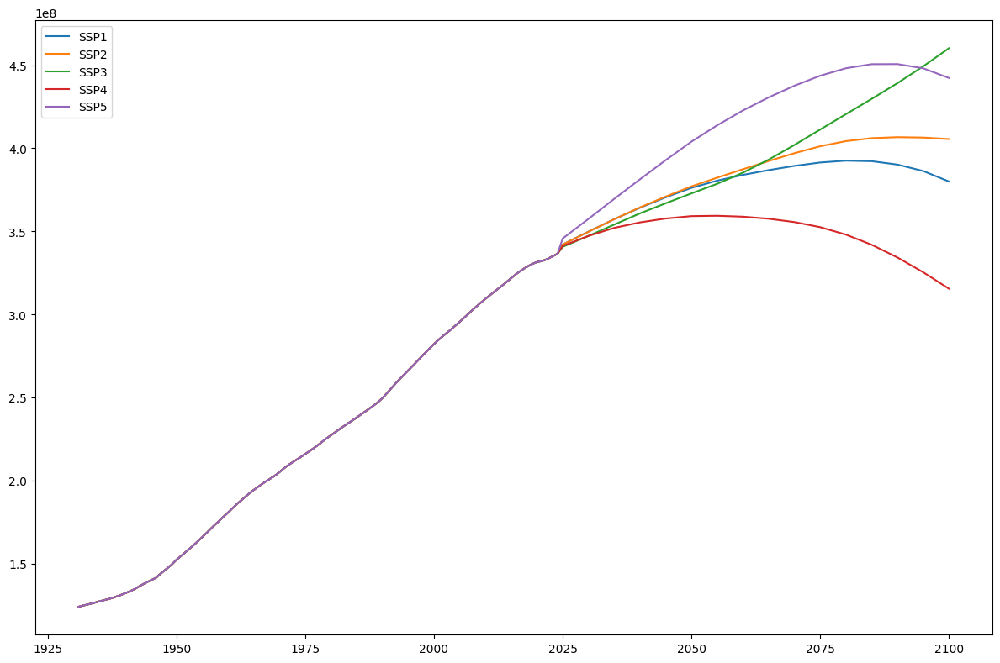

In [237]:
plt.plot(df_population.index,df_population['pop_ssp1'], label='SSP1')
plt.plot(df_population.index,df_population['pop_ssp2'], label='SSP2')
plt.plot(df_population.index,df_population['pop_ssp3'], label='SSP3')
plt.plot(df_population.index,df_population['pop_ssp4'], label='SSP4')
plt.plot(df_population.index,df_population['pop_ssp5'], label='SSP5')
plt.legend()

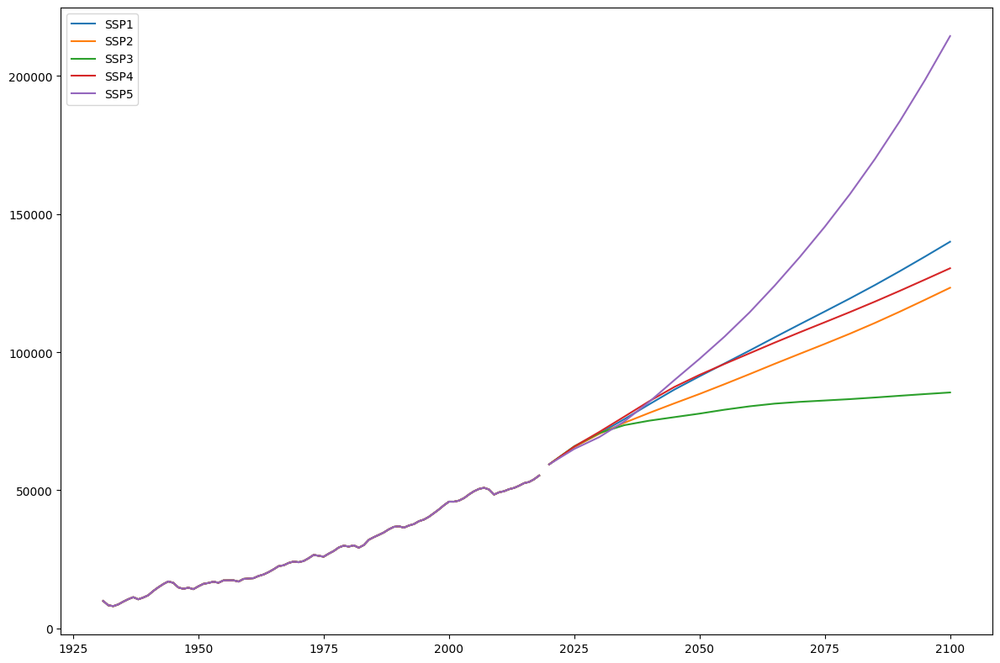

In [238]:
plt.plot(df_gdp.index,df_gdp['gdp_ssp1'], label='SSP1')
plt.plot(df_gdp.index,df_gdp['gdp_ssp2'], label='SSP2')
plt.plot(df_gdp.index,df_gdp['gdp_ssp3'], label='SSP3')
plt.plot(df_gdp.index,df_gdp['gdp_ssp4'], label='SSP4')
plt.plot(df_gdp.index,df_gdp['gdp_ssp5'], label='SSP5')
plt.legend()

## Perform MFA

In [239]:
## Define survival Function
def generate_lt(type, par1, par2):
    ''' Normal: par1  = mean, par2 = std. dev
        Weibull: par1 = shape, par2 = scale'''
    if type=='Normal':
        # Normal
        lt = {'Type': type, 'Mean': np.array([par1] * len(years)), 'StdDev': par2}
    elif type=='Weibull':
        # Weibull 
            lt = {'Type': type, 'Shape': np.array([par1]), 'Scale': np.array([par2])}
    return lt   

# For testing shapes
x=np.arange(1,170)
def weib(x,n,a):
    return (a/n) * (x/n)**(a-1) * np.exp(-(x/n)**a)

Text(0.5, 0, 'Age to Failuire')

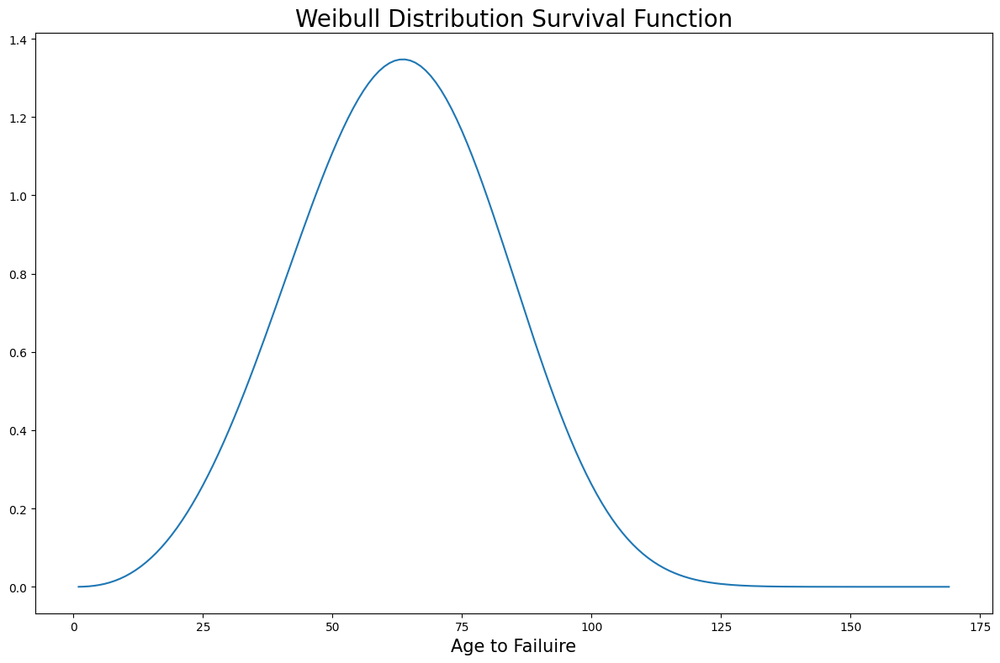

In [240]:
## See weibull shapes
lt_buildings = generate_lt('Weibull',par1=3.5,par2=70)

plt.plot(x, weib(x, lt_buildings['Scale'][0], lt_buildings['Shape'][0])*lt_buildings['Scale'][0])
plt.title('Weibull Distribution Survival Function', fontsize = 20)
plt.xlabel('Age to Failuire', fontsize = 15)

In [241]:
## Get params
years = df_steel_forecast.index

years = np.array(years)
n_years = len(years)

base_shape = 3.5
base_scale = 70
change_year = 2024
n_scenarios = 20


In [242]:
def build_lifetime_scenarios(inflow_series, years, base_shape=3.5, base_scale=69,
                               change_year=2024, n_scenarios=41):
    """
    Builds a dict of DSM results, one per lifetime scale scenario,
    for a given inflow series (e.g. ssp1, ssp2, ssp3...).
    """
    results = {}
    n_years = len(years)

    for i in range(n_scenarios):
        new_scale = base_scale + (i + 1)  # 70, 71, ..., 90

        shape_array = np.full(n_years, base_shape)
        scale_array = np.where(years <= change_year, base_scale, new_scale)

        steel_DSM = dsm.DynamicStockModel(
            t=years,
            i=np.array(inflow_series),
            lt={'Type': 'Weibull', 'Shape': shape_array, 'Scale': scale_array}
        )

        stock_by_cohort = steel_DSM.compute_s_c_inflow_driven()
        CheckStr = steel_DSM.dimension_check()
        S_steel = steel_DSM.compute_stock_total()
        O_C = steel_DSM.compute_o_c_from_s_c()
        DS_steel = steel_DSM.compute_stock_change()
        O_steel = steel_DSM.compute_outflow_total()

        results[f'scale_{new_scale}'] = {
            'dsm': steel_DSM,
            'stock_by_cohort': stock_by_cohort,
            'check': CheckStr,
            'S_steel': S_steel,
            'O_C': O_C,
            'DS_steel': DS_steel,
            'O_steel': O_steel,
            'lifetime_scale': new_scale,
        }

    return results

In [243]:
scenario_results_low  = build_lifetime_scenarios(df_steel_forecast['ssp3'], years)
scenario_results_mid  = build_lifetime_scenarios(df_steel_forecast['ssp2'], years)
scenario_results_high = build_lifetime_scenarios(df_steel_forecast['ssp4'], years)

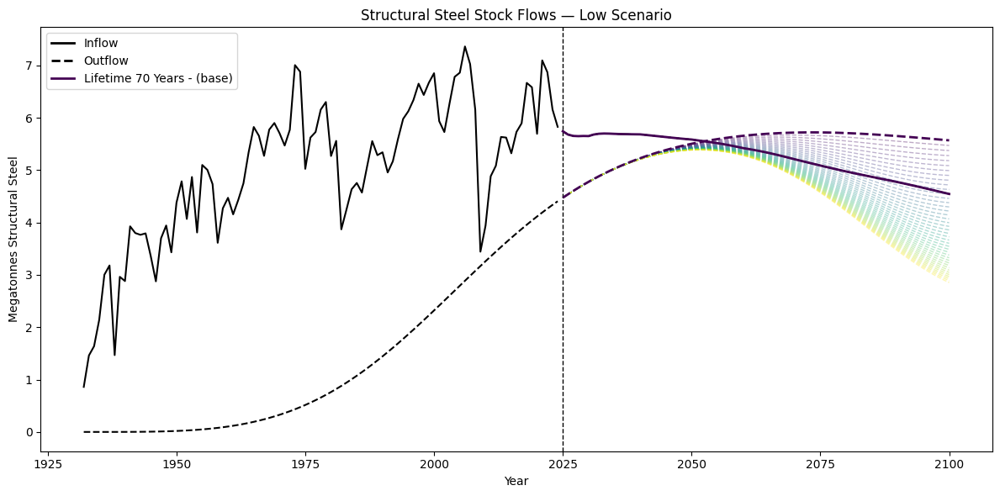

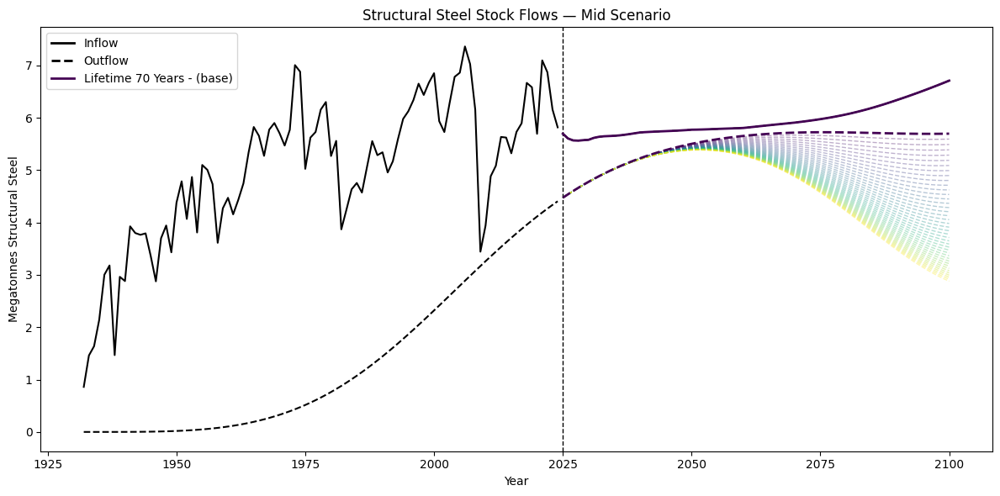

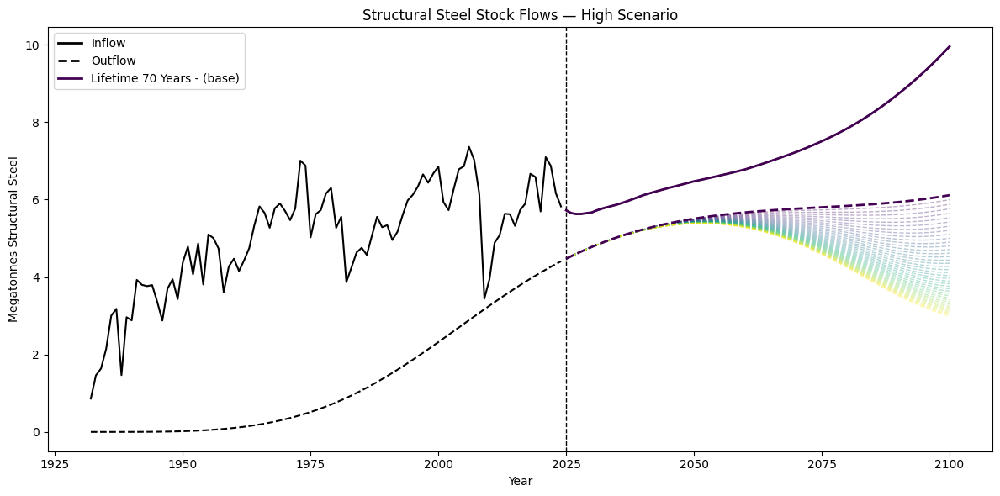

In [244]:
def plot_lifetime_scenarios(scenario_results, inflow_series, years, title,
                              change_year=2024, base_scale=70,
                              historical_outflow=None):
    fig, ax = plt.subplots(figsize=(12, 6))
    scale_values = sorted(
        int(k.split('_')[1]) for k in scenario_results.keys()
    )
    colors = cm.viridis(np.linspace(0, 1, len(scale_values)))
    inflow = np.array(inflow_series)
    mask = years > change_year
    for idx, scale in enumerate(scale_values):
        result = scenario_results[f'scale_{scale}']
        outflow = result['O_steel']
        is_base = (scale == base_scale)
        alpha = 1.0 if is_base else 0.35
        lw = 2.0 if is_base else 1.0
        zorder = 10 if is_base else 2
        ax.plot(years[mask], inflow[mask], color=colors[idx], alpha=alpha,
                linewidth=lw, zorder=zorder, linestyle='-')
        ax.plot(years[mask], outflow[mask], color=colors[idx], alpha=alpha,
                linewidth=lw, zorder=zorder, linestyle='--')

    hist_mask = years <= change_year
    ax.plot(years[hist_mask], inflow[hist_mask],
            color='black', linewidth=1.5, zorder=5)
    if historical_outflow is not None:
        # historical_outflow is already pre-sliced to the historical period — don't mask again
        ax.plot(years[hist_mask], np.array(historical_outflow),
                color='black', linestyle='--', linewidth=1.5, zorder=5)

    ax.axvline(change_year + 1, color='black', linestyle='--', linewidth=1)
    ax.set_xlabel('Year')
    ax.set_ylabel('Megatonnes Structural Steel')
    ax.set_title(title)
    legend_elements = [
        Line2D([0], [0], color='black', lw=2, label='Inflow'),
        Line2D([0], [0], color='black', lw=2, linestyle='--', label='Outflow'),
        Line2D([0], [0], color=colors[scale_values.index(base_scale)], lw=2,
               alpha=1.0, label=f'Lifetime {base_scale} Years - (base)'),
    ]
    ax.legend(handles=legend_elements, loc='upper left')
    plt.tight_layout()
    plt.show()
    return fig, ax


### Define Historic Steel Outflows
O_steel_full = scenario_results_mid['scale_70']['O_steel']
hist_mask = scenario_results_mid['scale_70']['dsm'].t <= 2024
O_steel_historical = O_steel_full[hist_mask]

# --- three separate calls, one per scenario family ---
fig_low, ax_low = plot_lifetime_scenarios(
    scenario_results_low, df_steel_forecast['ssp3'], years,
    title='Structural Steel Stock Flows — Low Scenario',
    historical_outflow=O_steel_historical
)

fig_mid, ax_mid = plot_lifetime_scenarios(
    scenario_results_mid, df_steel_forecast['ssp2'], years,
    title='Structural Steel Stock Flows — Mid Scenario',
    historical_outflow=O_steel_historical
)

fig_high, ax_high = plot_lifetime_scenarios(
    scenario_results_high, df_steel_forecast['ssp4'], years,
    title='Structural Steel Stock Flows — High Scenario',
    historical_outflow=O_steel_historical
)


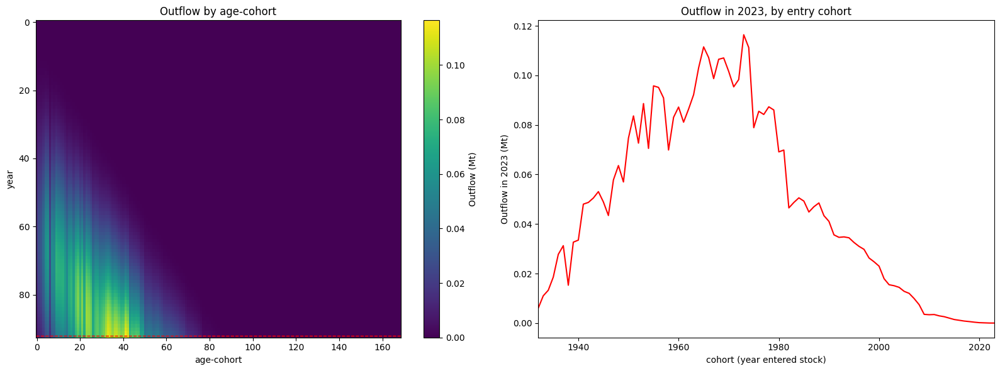

In [245]:
O_C_hist = scenario_results_mid['scale_70']['O_C'][hist_mask]  # shape (93, 169)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# --- Left: heatmap (same as before) ---
im = ax1.imshow(O_C_hist, interpolation='nearest', aspect='auto', cmap='viridis')
ax1.set_xlabel('age-cohort')
ax1.set_ylabel('year')
ax1.set_title('Outflow by age-cohort')
fig.colorbar(im, ax=ax1, label='Outflow (Mt)')

# highlight the row we're slicing out on the right
last_row_idx = O_C_hist.shape[0] - 1  # index for 2023 (last historical year)
ax1.axhline(last_row_idx, color='red', linestyle='--', linewidth=1)

# --- Right: single-year cohort slice ---
cohort_years = years  # full 1931-2100 cohort axis, length 169
outflow_2023 = O_C_hist[last_row_idx, :]

ax2.plot(cohort_years, outflow_2023, color='red', linewidth=1.5)
ax2.set_xlabel('cohort (year entered stock)')
ax2.set_ylabel('Outflow in 2023 (Mt)')
ax2.set_title('Outflow in 2023, by entry cohort')
ax2.set_xlim(cohort_years.min(), 2023)  # no point showing cohorts that don't exist yet

plt.tight_layout()
plt.show()

From here I need to calculate what percentage of outflow came from pre-1960 in 2023

### Convert to Tidy Data

In [246]:
def tidy_scenario_results(scenario_results, years, inflow_series=None):
    """
    Converts a scenario_results dict into two tidy DataFrames:
      - df_annual: one row per (scale, year, variable) for 1D series
                   (Inflow, Stock, Outflow, Stock_Change)
      - df_cohort: one row per (scale, year, cohort, variable) for 2D series
                   (Stock_by_cohort, Outflow_by_cohort)
    """
    annual_rows = []
    cohort_rows = []

    for scale_key, result in scenario_results.items():
        scale = result['lifetime_scale']

        # --- 1D annual series ---
        annual_vars = {
            'Stock': result['S_steel'],
            'Outflow': result['O_steel'],
            'Stock_Change': result['DS_steel'],
        }
        if inflow_series is not None:
            annual_vars['Inflow'] = np.array(inflow_series)

        for var_name, values in annual_vars.items():
            values = np.asarray(values)
            for yr, val in zip(years, values):
                annual_rows.append({
                    'scale': scale,
                    'year': yr,
                    'variable': var_name,
                    'value': val,
                })

        # --- 2D cohort-indexed series (year x cohort) ---
        cohort_vars = {
            'Stock_by_cohort': result['stock_by_cohort'],
            'Outflow_by_cohort': result['O_C'],
        }
        for var_name, matrix in cohort_vars.items():
            matrix = np.asarray(matrix)
            for yr_idx, yr in enumerate(years):
                for cohort_idx, cohort_yr in enumerate(years):
                    val = matrix[yr_idx, cohort_idx]
                    if val == 0:
                        continue  # skip structural zeros to keep table size manageable
                    cohort_rows.append({
                        'scale': scale,
                        'year': yr,
                        'cohort': cohort_yr,
                        'variable': var_name,
                        'value': val,
                    })

    df_annual = pd.DataFrame(annual_rows)
    df_cohort = pd.DataFrame(cohort_rows)
    return df_annual, df_cohort


In [247]:
df_tidy_low, df_cohort_low = tidy_scenario_results(scenario_results_low, years, inflow_series=df_steel_forecast['ssp3'])
df_tidy_mid, df_cohort_mid = tidy_scenario_results(scenario_results_mid, years, inflow_series=df_steel_forecast['ssp2'])
df_tidy_high, df_cohort_high = tidy_scenario_results(scenario_results_high, years, inflow_series=df_steel_forecast['ssp4'])

### Percent demand Satisfied by Outflows

In [248]:
def compute_outflow_inflow_ratio(df_tidy, start_year=2024, end_year=2100):
    """
    Pivots a tidy annual DataFrame (columns: scale, year, variable, value)
    to compute Outflow/Inflow ratio per (scale, year).
    """
    pivoted = df_tidy[df_tidy['variable'].isin(['Inflow', 'Outflow'])].pivot_table(
        index=['scale', 'year'], columns='variable', values='value'
    ).reset_index()

    pivoted['ratio'] = pivoted['Outflow'] / pivoted['Inflow']

    # restrict to the display window
    pivoted = pivoted[(pivoted['year'] >= start_year) & (pivoted['year'] <= end_year)]


    return pivoted


def plot_outflow_inflow_ratio(df_tidy, title, base_scale=70, start_year=2024, end_year=2100,
                                annotate_years=(2050, 2075, 2100)):
    ratio_df = compute_outflow_inflow_ratio(df_tidy, start_year=start_year, end_year=end_year)
    scales = sorted(ratio_df['scale'].unique())
    colors = cm.viridis(np.linspace(0, 1, len(scales)))

    fig, ax = plt.subplots(figsize=(10, 5))

    for idx, scale in enumerate(scales):
        subset = ratio_df[ratio_df['scale'] == scale].sort_values('year')
        is_base = (scale == base_scale)
        alpha = 1.0 if is_base else 0.4
        lw = 2.0 if is_base else 1.0
        zorder = 10 if is_base else 2

        ax.plot(subset['year'], subset['ratio'] * 100,
                color=colors[idx], alpha=alpha, linewidth=lw, zorder=zorder,
                label=f'Base - 70 Yr Lifetime' if is_base else None)

    # ax.set_ylabel('Percent of Inflows met by Outflows')
    ax.set_xlabel('Year')
    ax.set_title(title)
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:.0f}%'))
    ax.set_xlim(start_year, end_year)
    ax.legend(title='Scenario', loc='upper left')

    # --- annotate min/max ratio at each specified year ---
    for yr in annotate_years:
        year_slice = ratio_df[ratio_df['year'] == yr]
        if year_slice.empty:
            continue

        max_row = year_slice.loc[year_slice['ratio'].idxmax()]
        min_row = year_slice.loc[year_slice['ratio'].idxmin()]

        max_pct = max_row['ratio'] * 100
        min_pct = min_row['ratio'] * 100

        box_text = f"{yr}\nHigh: {max_pct:.0f}%\nLow: {min_pct:.0f}%"

        ax.annotate(
            box_text,
            xy=(yr, max_pct),
            xytext=(yr, min_pct - 8),  # offset above the highest line at that year
            ha='center', va='bottom', fontsize=8,
            bbox=dict(boxstyle='round,pad=0.4', facecolor='white', edgecolor='gray', alpha=0.9),
            zorder=20,
        )

        ax.vlines(
            x = yr, 
            ymin=min_pct, 
            ymax=max_pct, 
            color='black', 
            linestyle='-', 
            linewidth=2, 
            alpha=1, 
            zorder=1)

        ax.hlines(
            y=[min_pct, max_pct],
            xmin=yr - 0.5,
            xmax=yr + 0.5,
            color='black',
            linewidth=2,
            alpha=1,
            zorder=15,
    )

    plt.tight_layout()
    plt.show()
    return fig, ax



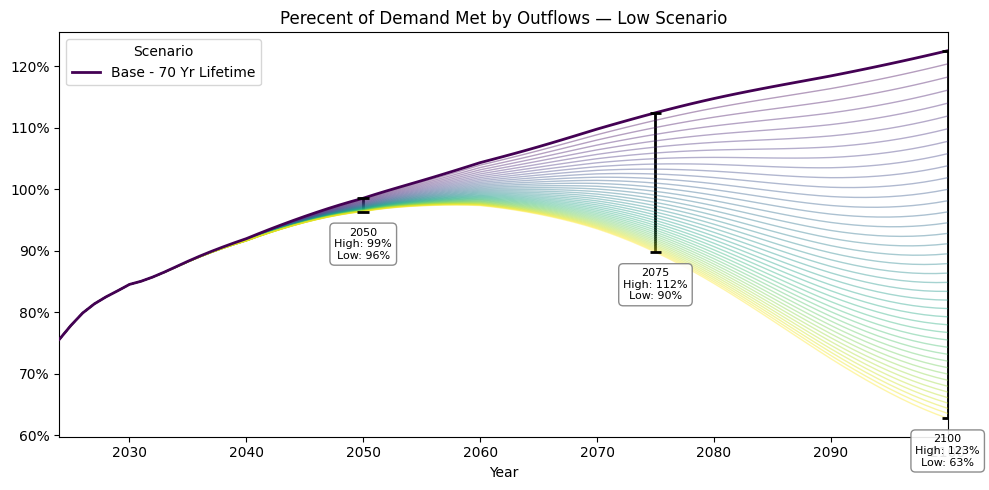

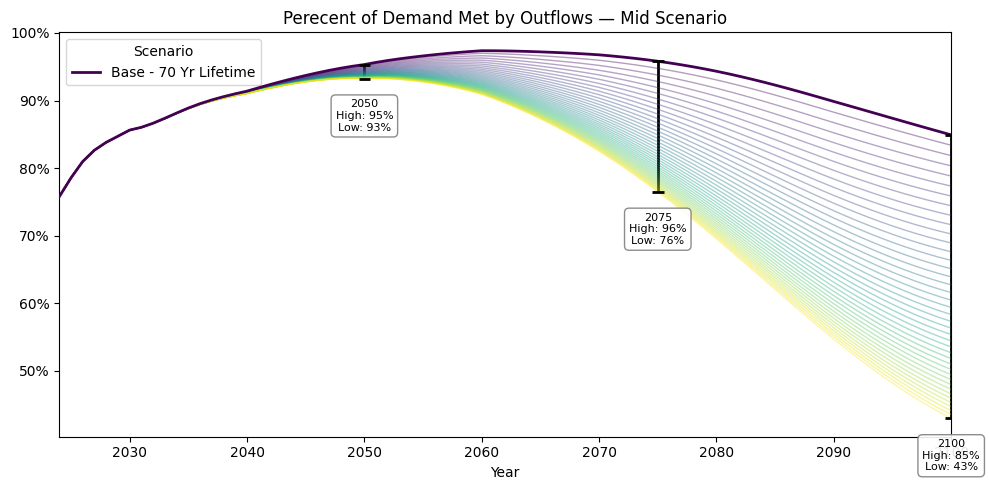

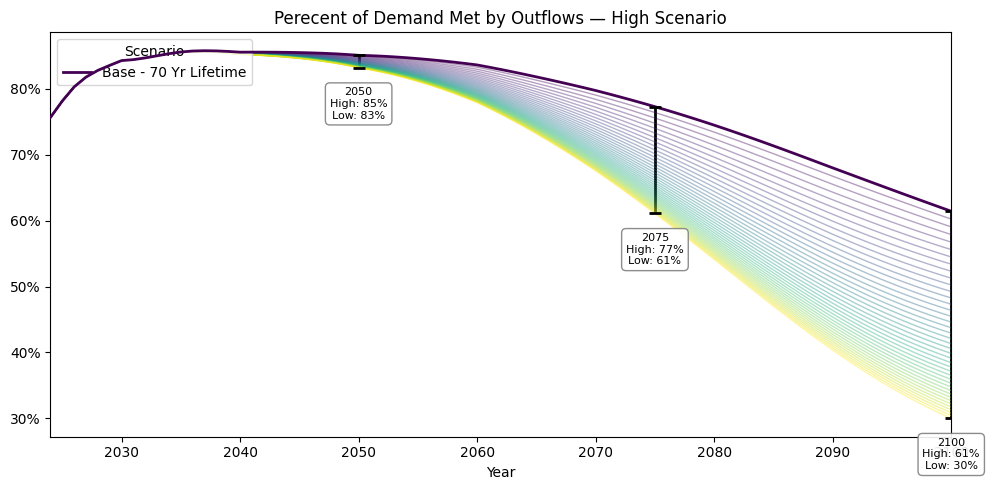

In [249]:
# --- three separate plots ---
fig_low, ax_low = plot_outflow_inflow_ratio(df_tidy_low, title='Perecent of Demand Met by Outflows — Low Scenario')
fig_mid, ax_mid = plot_outflow_inflow_ratio(df_tidy_mid, title='Perecent of Demand Met by Outflows — Mid Scenario')
fig_high, ax_high = plot_outflow_inflow_ratio(df_tidy_high, title='Perecent of Demand Met by Outflows — High Scenario')

### Old MFA

In [250]:
## Perform MFA ssp2

# steel_DSM_ssp2 = dsm.DynamicStockModel(t = np.array(years), i = np.array(df_steel_forecast['ssp2']), 
#                                   lt = {'Type': 'Weibull', 'Shape': np.array([2.25]), 
#                                         'Scale': np.array([85]) })

# stock_by_cohort =  steel_DSM_ssp2.compute_s_c_inflow_driven()
# CheckStr = steel_DSM_ssp2.dimension_check()
# S_steel = steel_DSM_ssp2.compute_stock_total() 
# O_C = steel_DSM_ssp2.compute_o_c_from_s_c()
# DS_steel = steel_DSM_ssp2.compute_stock_change()
# O_steel = steel_DSM_ssp2.compute_outflow_total()

In [251]:
## Perform MFA ssp3

# steel_DSM_ssp3 = dsm.DynamicStockModel(t = np.array(years), i = np.array(df_steel_forecast['ssp3']), 
#                                   lt = {'Type': 'Weibull', 'Shape': np.array([2.25]), 
#                                         'Scale': np.array([85]) })

# stock_by_cohort =  steel_DSM_ssp3.compute_s_c_inflow_driven()
# CheckStr = steel_DSM_ssp3.dimension_check()
# S_steel = steel_DSM_ssp3.compute_stock_total() 
# O_C = steel_DSM_ssp3.compute_o_c_from_s_c()
# DS_steel = steel_DSM_ssp3.compute_stock_change()
# O_steel = steel_DSM_ssp3.compute_outflow_total()

In [252]:
## Perform MFA ssp4

# steel_DSM_ssp4 = dsm.DynamicStockModel(t = np.array(years), i = np.array(df_steel_forecast['ssp4']), 
#                                   lt = {'Type': 'Weibull', 'Shape': np.array([2.25]), 
#                                         'Scale': np.array([85]) })

# stock_by_cohort =  steel_DSM_ssp4.compute_s_c_inflow_driven()
# CheckStr = steel_DSM_ssp4.dimension_check()
# S_steel = steel_DSM_ssp4.compute_stock_total() 
# O_C = steel_DSM_ssp4.compute_o_c_from_s_c()
# DS_steel = steel_DSM_ssp4.compute_stock_change()
# O_steel = steel_DSM_ssp4.compute_outflow_total()

In [253]:
## Perform MFA ssp5

# steel_DSM_ssp5 = dsm.DynamicStockModel(t = np.array(years), i = np.array(df_steel_forecast['ssp5']), 
#                                   lt = {'Type': 'Weibull', 'Shape': np.array([2.25]), 
#                                         'Scale': np.array([85]) })

# stock_by_cohort =  steel_DSM_ssp5.compute_s_c_inflow_driven()
# CheckStr = steel_DSM_ssp5.dimension_check()
# S_steel = steel_DSM_ssp5.compute_stock_total() 
# O_C = steel_DSM_ssp5.compute_o_c_from_s_c()
# DS_steel = steel_DSM_ssp5.compute_stock_change()
# O_steel = steel_DSM_ssp5.compute_outflow_total()

In [254]:
# ### Forecast with MAE bands ###

# fig, ax = plt.subplots(figsize=(12,6))

# ax.plot(steel_DSM_ssp1.t[:93], steel_DSM_ssp1.i[:93], color='black')
# ax.plot(steel_DSM_ssp1.t[93:], steel_DSM_ssp1.i[93:], color='#378ADD')
# ax.plot(steel_DSM_ssp2.t[93:], steel_DSM_ssp2.i[93:], color='#E07B3F')
# ax.plot(steel_DSM_ssp3.t[93:], steel_DSM_ssp3.i[93:], color='#4CAF82')
# ax.plot(steel_DSM_ssp4.t[93:], steel_DSM_ssp4.i[93:], color='#A855F7')
# ax.plot(steel_DSM_ssp5.t[93:], steel_DSM_ssp5.i[93:], color='#D85A30')

# ax.plot(steel_DSM_ssp1.t[:93], steel_DSM_ssp1.o[:93], color='black', ls="--")
# ax.plot(steel_DSM_ssp1.t[93:], steel_DSM_ssp1.o[93:], color='#378ADD', ls="--")
# ax.plot(steel_DSM_ssp2.t[93:], steel_DSM_ssp2.o[93:], color='#E07B3F', ls="--")
# ax.plot(steel_DSM_ssp3.t[93:], steel_DSM_ssp3.o[93:], color='#4CAF82', ls="--")
# ax.plot(steel_DSM_ssp4.t[93:], steel_DSM_ssp4.o[93:], color='#A855F7', ls="--")
# ax.plot(steel_DSM_ssp5.t[93:], steel_DSM_ssp5.o[93:], color='#D85A30', ls="--")

# # --- fill_between bands around each inflow line (±0.610) ---
# # ax.fill_between(steel_DSM_ssp1.t[:93],
# #                  steel_DSM_ssp1.i[:93] - 0.610, steel_DSM_ssp1.i[:93] + 0.610,
# #                  color='black', alpha=0.15, linewidth=0)
# ax.fill_between(steel_DSM_ssp1.t[93:],
#                  steel_DSM_ssp1.i[93:] - 0.610, steel_DSM_ssp1.i[93:] + 0.610,
#                  color='#378ADD', alpha=0.15, linewidth=0)
# ax.fill_between(steel_DSM_ssp2.t[93:],
#                  steel_DSM_ssp2.i[93:] - 0.610, steel_DSM_ssp2.i[93:] + 0.610,
#                  color='#E07B3F', alpha=0.15, linewidth=0)
# ax.fill_between(steel_DSM_ssp3.t[93:],
#                  steel_DSM_ssp3.i[93:] - 0.610, steel_DSM_ssp3.i[93:] + 0.610,
#                  color='#4CAF82', alpha=0.15, linewidth=0)
# ax.fill_between(steel_DSM_ssp4.t[93:],
#                  steel_DSM_ssp4.i[93:] - 0.610, steel_DSM_ssp4.i[93:] + 0.610,
#                  color='#A855F7', alpha=0.15, linewidth=0)
# ax.fill_between(steel_DSM_ssp5.t[93:],
#                  steel_DSM_ssp5.i[93:] - 0.610, steel_DSM_ssp5.i[93:] + 0.610,
#                  color='#D85A30', alpha=0.15, linewidth=0)

# ax.plot([2024,2024],[0,12], color='k', linestyle='--')
# plt.xlabel('Year', fontsize=15)
# plt.ylabel('Megatonnes Structural Steel', fontsize=15)
# plt.title('Different Scenario Stock Flows of Structural Steel 1931-2100 - Power Model', fontsize=16)

# scenario_handles = [
#     mlines.Line2D([], [], color='#378ADD', linestyle='-', label='SSP1'),
#     mlines.Line2D([], [], color='#E07B3F', linestyle='-', label='SSP2'),
#     mlines.Line2D([], [], color='#4CAF82', linestyle='-', label='SSP3'),
#     mlines.Line2D([], [], color='#A855F7', linestyle='-', label='SSP4'),
#     mlines.Line2D([], [], color='#D85A30', linestyle='-', label='SSP5'),
# ]

# leg1 = ax.legend(handles=scenario_handles, title='Scenario', loc='upper left')
# ax.add_artist(leg1)

# flow_handles = [
#     mlines.Line2D([], [], color='black', linestyle='-', label='Inflow'),
#     mlines.Line2D([], [], color='black', linestyle='--', label='Outflow'),
# ]

# ax.set_ylim(0,)
# ax.legend(handles=flow_handles, title='Flow Type', loc='upper left', bbox_to_anchor=(0.09, 1))
# plt.show()

In [255]:
# start_year = 1931
# n_years = len(steel_DSM_ssp1.t)
# years = np.arange(start_year, start_year + n_years)

# # Build all SSP flow dataframes
# flow_dfs = {}

# for s in range(1, 6):   # SSP1–SSP5
#     model = globals()[f"steel_DSM_ssp{s}"]   # get steel_DSM_ssp1, etc.

#     df = pd.DataFrame({
#         f"inflow_ssp{s}":  model.i,
#         f"outflow_ssp{s}": model.o,
#     }, index=years)

#     df.index.name = "Year"

#     flow_dfs[f"ssp{s}"] = df

# all_flows = pd.concat(flow_dfs.values(), axis=1)

In [256]:
# all_flows.loc[2024]

Deconstruction / demolition emissions excluded, assumed to be the same for this. However, future versions of this model should note that deconstruction seemingly tends to have lower emissions associated with it

In [257]:
# total_flows['flows delta'] = total_flows['Total Inflow'] - total_flows['Total Outflow']
# total_flows['demand percentage'] = total_flows['Total Outflow'] / total_flows['Total Inflow']

In [258]:
# all_flows['demand percentage_ssp1'] = all_flows['outflow_ssp1'] / all_flows['inflow_ssp1']
# all_flows['demand percentage_ssp2'] = all_flows['outflow_ssp2'] / all_flows['inflow_ssp2']
# all_flows['demand percentage_ssp3'] = all_flows['outflow_ssp3'] / all_flows['inflow_ssp3']
# all_flows['demand percentage_ssp4'] = all_flows['outflow_ssp4'] / all_flows['inflow_ssp4']
# all_flows['demand percentage_ssp5'] = all_flows['outflow_ssp5'] / all_flows['inflow_ssp5']


In [259]:
# fig,ax = plt.subplots(figsize = (10,5))

# years = all_flows.loc[2024:2100].index
# ax.plot(years, all_flows['demand percentage_ssp1'].loc[2024:2100], color = '#378ADD')
# ax.plot(years, all_flows['demand percentage_ssp2'].loc[2024:2100], color = '#E07B3F')
# ax.plot(years, all_flows['demand percentage_ssp3'].loc[2024:2100], color = '#4CAF82')
# ax.plot(years, all_flows['demand percentage_ssp4'].loc[2024:2100], color = '#A855F7')
# ax.plot(years, all_flows['demand percentage_ssp5'].loc[2024:2100], color = '#D85A30')

# plt.ylabel('Percent of Inflows met by Outflows')
# plt.title('Ratio of Outflows to Inflows', fontsize = 20)
# scenario_handles = [
#     mlines.Line2D([], [], color='#378ADD',        linestyle='-', label='SSP1'),
#     mlines.Line2D([], [], color='#E07B3F',       linestyle='-', label='SSP2'),
#     mlines.Line2D([], [], color='#4CAF82',      linestyle='-', label='SSP3'),
#     mlines.Line2D([], [], color='#A855F7',      linestyle='-', label='SSP4'),
#     mlines.Line2D([], [], color='#D85A30',         linestyle='-', label='SSP5'),
# ]

# ax.yaxis.set_major_formatter(mtick.PercentFormatter(1))
# ax.legend(handles=scenario_handles, title='Scenario', loc='upper left')

## Scenario Analysis of Reuse Rates and Green Steel adoption

In [260]:
## Make QMC Ceilings

# Fixed, hand-adjustable curve-shape parameters — not sampled
G_reuse, M_reuse = 0.15, 2055   # adoption speed / inflection year for reuse
G_green, M_green = 0.15, 2055   # adoption speed / inflection year for green steel

def generate_grid_ceilings(step=10):
    """
    Replaces QMC sampling with a regular grid of (B_reuse, B_green) ceilings,
    each ranging 0-100% in `step`-sized increments. A fixed at 0; G, M fixed constants.
    """
    ceilings = np.arange(0, 100 + step, step) / 100  # 0.0, 0.1, ..., 1.0
    combos = list(itertools.product(ceilings, ceilings))

    df_params = pd.DataFrame(combos, columns=['B_reuse', 'B_green'])
    df_params['A_reuse'] = 0.0
    df_params['A_green'] = 0.0
    df_params['G_reuse'] = G_reuse
    df_params['M_reuse'] = M_reuse
    df_params['G_green'] = G_green
    df_params['M_green'] = M_green
    df_params['draw_id'] = np.arange(len(df_params))
    return df_params


param_df = generate_grid_ceilings(step=10)
print(param_df.shape)  # (121, 7)
param_df.head()

(121, 9)


,B_reuse,B_green,A_reuse,A_green,G_reuse,M_reuse,G_green,M_green,draw_id
0,0.0,0.0,0.0,0.0,0.15,2055,0.15,2055,0
1,0.0,0.1,0.0,0.0,0.15,2055,0.15,2055,1
2,0.0,0.2,0.0,0.0,0.15,2055,0.15,2055,2
3,0.0,0.3,0.0,0.0,0.15,2055,0.15,2055,3
4,0.0,0.4,0.0,0.0,0.15,2055,0.15,2055,4


In [261]:
### Define Scenarios

def logistic_curve(t, A, B, G, M):
    return A + (B - A) / (1 + np.exp(-G * (t - M)))

def run_qmc_scenarios(scenario_results, inflow_series, years, param_df,
                       change_year=2024, end_year=2100):
    """
    For each lifetime scale in scenario_results, applies all 1000 QMC draws
    (B_reuse, B_green ceilings; fixed A/G/M) to compute:
      - reuse_rate(t) and reused_outflow(t)
      - production_demand(t) = max(demand_total(t) - reused_outflow(t), 0)
      - green_share(t) and the green/conventional split of production_demand
    Fully vectorized: one (n_draws x n_years) array per scale, no per-draw loop.
    """
    years = np.array(years)
    mask = (years >= change_year) & (years <= end_year)
    t = years[mask]                      # shape (n_years,)
    demand_total = np.array(inflow_series)[mask]   # shape (n_years,)

    # param arrays, reshaped to broadcast against (n_draws, n_years)
    A_r = param_df['A_reuse'].values[:, None]
    B_r = param_df['B_reuse'].values[:, None]
    G_r = param_df['G_reuse'].values[:, None]
    M_r = param_df['M_reuse'].values[:, None]

    A_g = param_df['A_green'].values[:, None]
    B_g = param_df['B_green'].values[:, None]
    G_g = param_df['G_green'].values[:, None]
    M_g = param_df['M_green'].values[:, None]

    draw_ids = param_df['draw_id'].values
    n_draws = len(param_df)
    n_years = len(t)

    frames = []
    for scale_key, result in scenario_results.items():
        scale = result['lifetime_scale']
        outflow_total = np.array(result['O_steel'])[mask]   # shape (n_years,)

        # reuse adoption curve, applied to outflow
        reuse_rate = logistic_curve(t[None, :], A_r, B_r, G_r, M_r)   # (n_draws, n_years)
        reused_outflow = reuse_rate * outflow_total[None, :]

        # production demand = total demand minus what reuse covers, floored at 0
        production_demand = np.maximum(demand_total[None, :] - reused_outflow, 0)

        # green-steel share of that production demand
        green_share = logistic_curve(t[None, :], A_g, B_g, G_g, M_g)
        green_share = np.clip(green_share, 0, 1)
        green_production = green_share * production_demand
        conventional_production = (1 - green_share) * production_demand

        frame = pd.DataFrame({
            'scale': scale,
            'draw_id': np.repeat(draw_ids, n_years),
            'year': np.tile(t, n_draws),
            'reuse_rate': reuse_rate.ravel(),
            'reused_outflow': reused_outflow.ravel(),
            'production_demand': production_demand.ravel(),
            'green_share': green_share.ravel(),
            'green_production': green_production.ravel(),
            'conventional_production': conventional_production.ravel(),
        })
        frames.append(frame)

    return pd.concat(frames, ignore_index=True)

In [262]:
df_qmc_low  = run_qmc_scenarios(scenario_results_low,  df_steel_forecast['ssp3'], years, param_df)
df_qmc_mid  = run_qmc_scenarios(scenario_results_mid,  df_steel_forecast['ssp2'], years, param_df)
df_qmc_high = run_qmc_scenarios(scenario_results_high, df_steel_forecast['ssp4'], years, param_df)

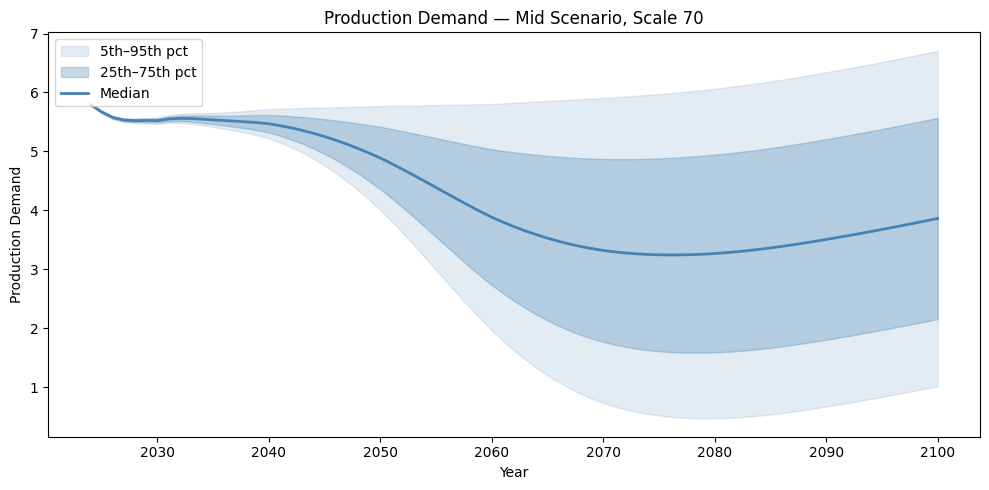

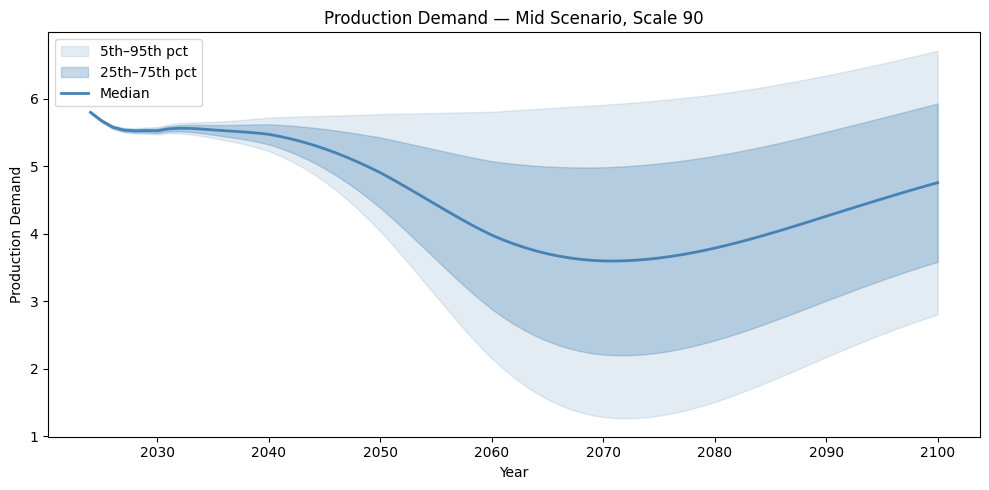

In [263]:
def plot_fan_chart(df_qmc, scale, value_col='production_demand', title=None,
                    percentiles=(5, 25, 50, 75, 95), color='steelblue'):
    """
    Plots a fan chart (percentile bands across QMC draws) for a single scale.
    """
    subset = df_qmc[df_qmc['scale'] == scale]

    # pivot so rows=year, columns=draw_id, values=value_col
    pivoted = subset.pivot(index='year', columns='draw_id', values=value_col)

    years_arr = pivoted.index.values
    pct_values = {p: pivoted.quantile(p / 100, axis=1).values for p in percentiles}

    fig, ax = plt.subplots(figsize=(10, 5))

    # shade outer band (5-95) and inner band (25-75), if present
    if 5 in pct_values and 95 in pct_values:
        ax.fill_between(years_arr, pct_values[5], pct_values[95],
                         color=color, alpha=0.15, label='5th–95th pct')
    if 25 in pct_values and 75 in pct_values:
        ax.fill_between(years_arr, pct_values[25], pct_values[75],
                         color=color, alpha=0.3, label='25th–75th pct')

    # median line
    if 50 in pct_values:
        ax.plot(years_arr, pct_values[50], color=color, linewidth=2, label='Median')

    ax.set_xlabel('Year')
    ax.set_ylabel(value_col.replace('_', ' ').title())
    ax.set_title(title or f'{value_col.replace("_", " ").title()} — Scale {scale}')
    ax.legend(loc='upper left')

    plt.tight_layout()
    plt.show()
    return fig, ax


# quick check on the mid scenario, scale 70
fig, ax = plot_fan_chart(df_qmc_mid, scale=70, value_col='production_demand',
                          title='Production Demand — Mid Scenario, Scale 70')
fig, ax = plot_fan_chart(df_qmc_mid, scale=90, value_col='production_demand',
                          title='Production Demand — Mid Scenario, Scale 90')

## Make simple sankey for 2019

In [264]:
# outflow = all_flows['outflow_ssp1'].loc[2019]*.98
# waste = all_flows['outflow_ssp1'].loc[2019]*.02
# inflow = all_flows['inflow_ssp1'].loc[2019]
# scrap = df_recycling['scrap'].loc[2019]+df_recycling['Exports'].loc[2019]-df_recycling['Imports'].loc[2019] - outflow
# virgin = 32000
# other_use = scrap + virgin - inflow
# inflow_reuse = inflow - outflow
# other_reuse = scrap + virgin - inflow_reuse

In [265]:
# import plotly.io as pio
# pio.renderers.default = "browser"

In [266]:
# fig = go.Figure(go.Sankey(
#     arrangement = "snap",
#     node = {
#         'label': ["Virgin", " Scrap", 'Feedstock', "EAF Processing","Fabrication","Built Environment","Construction Scrap", "Waste", "Other Use"],
#         # 'x' : [0.1, 0.1, 0.3, 0.5, 0.7, 0.8, 0.8, 0.7],
#         # 'y' : [0.7, 0.5, 0.5, 0.4, 0.4, 0.3, 0.5, 0.7]
#     },
#     link = {
#         "source" : [0,1,2,3,4,5,5,6,2],
#         "target" : [2,2,3,4,5,6,7,1,8],
#         "value" : [virgin,scrap,inflow,inflow,inflow,outflow,waste,outflow,other_use]
#     }

# ))

# fig.show()

In [267]:
# fig = go.Figure(go.Sankey(
#     arrangement = "snap",
#     node = {
#         'label': ["Virgin", " Scrap", 'Feedstock', "EAF Processing","Fabrication","Built Environment","structural Steel Scrap", "Waste", "Other Use"],
#         # 'x' : [0.1, 0.1, 0.3, 0.5, 0.7, 0.8, 0.8, 0.7],
#         # 'y' : [0.7, 0.5, 0.5, 0.4, 0.4, 0.3, 0.5, 0.7]
#     },
#     link = {
#         "source" : [0,1,2,3,4,5,5,6,2],
#         "target" : [2,2,3,4,5,6,7,4,8],
#         "value" : [virgin,scrap,inflow_reuse,inflow_reuse,inflow,outflow,waste,outflow,other_reuse]
#     }

# ))

# fig.show()

## Static LCA

In [268]:
conventional_co2 = (.898 + ((0.026+0.0824)*1.0771))*1e6
reuse_co2 = ((0.0262+0.0824)*1.0771)*1e6
green_co2 = conventional_co2 * 0.33

In [269]:
.153 / (conventional_co2 / 1e6)

0.15077491803855747

In [270]:
print(conventional_co2 / 1e6)
print(reuse_co2 / 1e6)
print(green_co2 / 1e6)

1.01475764
0.11697305999999999
0.33487002120000003


In [271]:
## Energy Coefficients
conventional_mj = 1730+12800 + ((1.11 + 15 + 503 + 1460) * 1.0771)
reuse_mj = ((1.11 + 15 + 503 + 1460) * 1.0771)
green_mj = conventional_mj * 1.13

In [272]:
print(conventional_mj)
print(reuse_mj)
print(green_mj)

16661.699381
2131.699381
18827.720300529996


In [273]:
def add_carbon_emissions(df_qmc, conventional_co2, reuse_co2, green_co2):
    """
    Adds a carbon_emissions column to a QMC results DataFrame using:
      emissions = conventional_production * conventional_co2
                + green_production * green_co2
                + reused_outflow * reuse_co2
    Coefficients are expected in units of tCO2 per unit of production
    (e.g. tCO2/Mt if your flows are in Mt — make sure units line up).
    """
    df_qmc = df_qmc.copy()
    df_qmc['carbon_emissions'] = (
        df_qmc['conventional_production'] * conventional_co2
        + df_qmc['green_production'] * green_co2
        + df_qmc['reused_outflow'] * reuse_co2
    )
    return df_qmc


In [274]:
def add_energy_usage(df_qmc, conventional_mj, reuse_mj, green_mj):

    df_qmc = df_qmc.copy()
    df_qmc['energy_usage'] = (
        df_qmc['conventional_production'] * conventional_mj
        + df_qmc['green_production'] * green_mj
        + df_qmc['reused_outflow'] * reuse_mj
    )
    return df_qmc


In [275]:
df_qmc_low  = add_carbon_emissions(df_qmc_low,  conventional_co2, reuse_co2, green_co2)
df_qmc_mid  = add_carbon_emissions(df_qmc_mid,  conventional_co2, reuse_co2, green_co2)
df_qmc_high = add_carbon_emissions(df_qmc_high, conventional_co2, reuse_co2, green_co2)

In [276]:
df_qmc_low  = add_energy_usage(df_qmc_low,  conventional_mj, reuse_mj, green_mj)
df_qmc_mid  = add_energy_usage(df_qmc_mid,  conventional_mj, reuse_mj, green_mj)
df_qmc_high = add_energy_usage(df_qmc_high, conventional_mj, reuse_mj, green_mj)

In [277]:
df_qmc_mid

,scale,draw_id,year,reuse_rate,reused_outflow,production_demand,green_share,green_production,conventional_production,carbon_emissions,energy_usage
0,70,0,2024,0.000000,0.000000,5.815996,0.000000,0.000000,5.815996,5.901826e+06,96904.378054
1,70,0,2025,0.000000,0.000000,5.694787,0.000000,0.000000,5.694787,5.778828e+06,94884.822942
2,70,0,2026,0.000000,0.000000,5.604331,0.000000,0.000000,5.604331,5.687038e+06,93377.684530
3,70,0,2027,0.000000,0.000000,5.566765,0.000000,0.000000,5.566765,5.648917e+06,92751.763397
4,70,0,2028,0.000000,0.000000,5.562053,0.000000,0.000000,5.562053,5.644136e+06,92673.262593
...,...,...,...,...,...,...,...,...,...,...,...
381992,110,120,2096,0.997871,3.071863,3.481467,0.997871,3.474056,0.007412,1.530204e+06,72080.328831
381993,110,120,2097,0.998167,3.017807,3.573267,0.998167,3.566718,0.006550,1.554035e+06,73695.345067
381994,110,120,2098,0.998422,2.966950,3.662548,0.998422,3.656768,0.005780,1.577460e+06,75269.548453
381995,110,120,2099,0.998641,2.919518,3.749060,0.998641,3.743967,0.005093,1.600415e+06,76798.752298


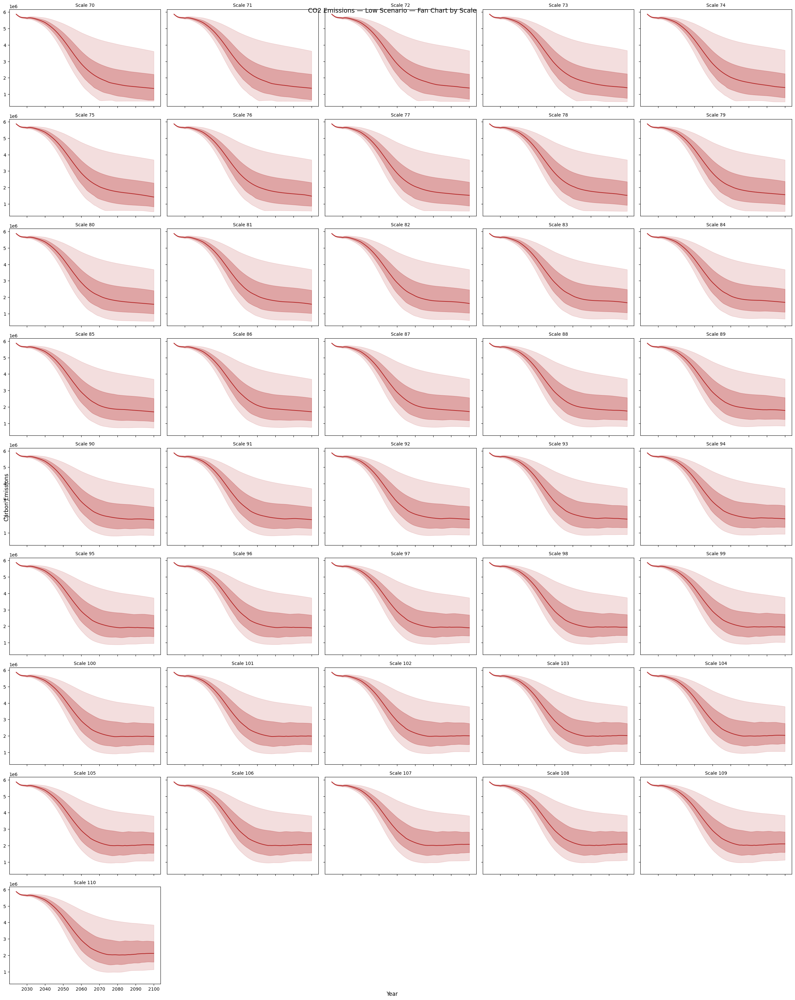

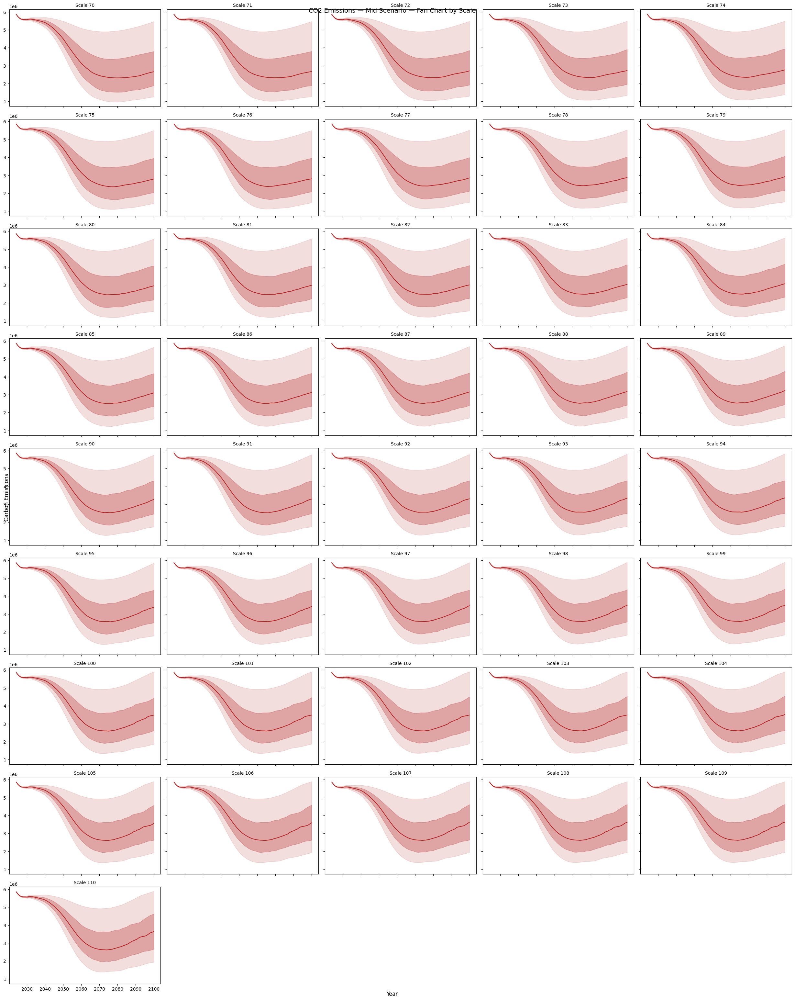

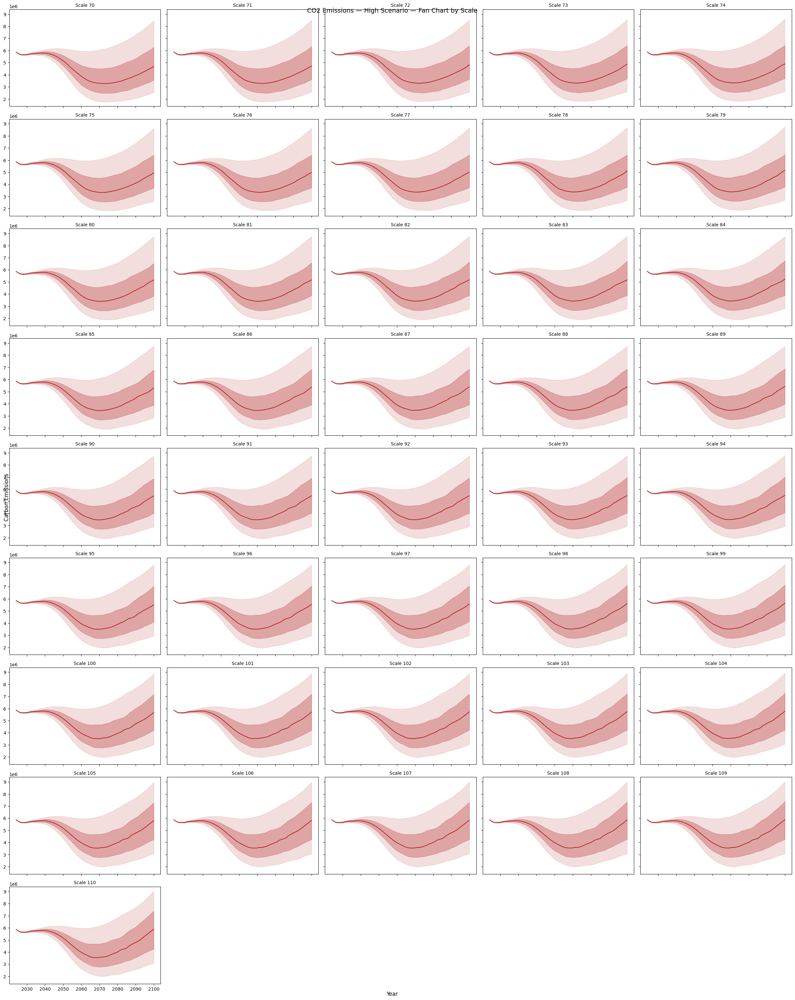

In [278]:
def plot_fan_chart_grid(df_qmc, value_col='carbon_emissions', title_prefix='CO2 Emissions',
                         percentiles=(5, 25, 50, 75, 95), color='firebrick', ncols=3):
    """
    Plots a grid of fan charts, one subplot per scale, for a single SSP scenario's df_qmc.
    """
    scales = sorted(df_qmc['scale'].unique())
    n_scales = len(scales)
    nrows = int(np.ceil(n_scales / ncols))

    fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 3.5 * nrows), sharex=True, sharey=True)
    axes = np.atleast_1d(axes).ravel()

    for idx, scale in enumerate(scales):
        ax = axes[idx]
        subset = df_qmc[df_qmc['scale'] == scale]
        pivoted = subset.pivot(index='year', columns='draw_id', values=value_col)
        years_arr = pivoted.index.values
        pct_values = {p: pivoted.quantile(p / 100, axis=1).values for p in percentiles}

        if 5 in pct_values and 95 in pct_values:
            ax.fill_between(years_arr, pct_values[5], pct_values[95], color=color, alpha=0.15)
        if 25 in pct_values and 75 in pct_values:
            ax.fill_between(years_arr, pct_values[25], pct_values[75], color=color, alpha=0.3)
        if 50 in pct_values:
            ax.plot(years_arr, pct_values[50], color=color, linewidth=1.5)

        ax.set_title(f'Scale {int(scale)}', fontsize=10)

    # hide any unused subplots
    for idx in range(n_scales, len(axes)):
        axes[idx].axis('off')

    fig.suptitle(f'{title_prefix} — Fan Chart by Scale', fontsize=14)
    fig.supxlabel('Year')
    fig.supylabel(value_col.replace('_', ' ').title())
    plt.tight_layout()
    plt.show()
    return fig, axes


# one grid per SSP scenario
fig_low, axes_low   = plot_fan_chart_grid(df_qmc_low,  title_prefix='CO2 Emissions — Low Scenario', ncols=5)
fig_mid, axes_mid   = plot_fan_chart_grid(df_qmc_mid,  title_prefix='CO2 Emissions — Mid Scenario', ncols=5)
fig_high, axes_high = plot_fan_chart_grid(df_qmc_high, title_prefix='CO2 Emissions — High Scenario', ncols=5)

In [279]:
df_qmc_high

,scale,draw_id,year,reuse_rate,reused_outflow,production_demand,green_share,green_production,conventional_production,carbon_emissions,energy_usage
0,70,0,2024,0.000000,0.000000,5.821644,0.000000,0.000000,5.821644,5.907558e+06,96998.480534
1,70,0,2025,0.000000,0.000000,5.722451,0.000000,0.000000,5.722451,5.806901e+06,95345.757905
2,70,0,2026,0.000000,0.000000,5.650801,0.000000,0.000000,5.650801,5.734193e+06,94151.944375
3,70,0,2027,0.000000,0.000000,5.625290,0.000000,0.000000,5.625290,5.708306e+06,93726.886222
4,70,0,2028,0.000000,0.000000,5.629552,0.000000,0.000000,5.629552,5.712631e+06,93797.911125
...,...,...,...,...,...,...,...,...,...,...,...
381992,110,120,2096,0.997871,3.155799,6.264026,0.997871,6.250691,0.013336,2.475845e+06,124635.667358
381993,110,120,2097,0.998167,3.107231,6.440192,0.998167,6.428388,0.011804,2.528115e+06,127852.254955
381994,110,120,2098,0.998422,3.062130,6.616677,0.998422,6.606236,0.010441,2.581013e+06,131081.876907
381995,110,120,2099,0.998641,3.020729,6.793330,0.998641,6.784101,0.009229,2.634501e+06,134322.211316


In [280]:
# ---------------------------------------------------------------
# 1. Baseline emissions factor (2024), tCO2 per ton steel
# ---------------------------------------------------------------
conventional_co2 = (.898 + ((0.026 + 0.0824) * 1.0771)) * 1e6
 
# ---------------------------------------------------------------
# 2. Demand forecast, trimmed to 2024-2100
#    (df_steel_forecast is assumed to already exist in your environment,
#     indexed by year, with an 'ssp2' column)
# ---------------------------------------------------------------
demand = df_steel_forecast['ssp2'].loc[2024:2100]
years = demand.index.astype(int)
 
# ---------------------------------------------------------------
# 3. Emissions factor trajectory
#    - Simple linear decline: 30% total reduction from 2024 to 2100,
#      no kink/step at 2030
# ---------------------------------------------------------------
START_YEAR = 2024
END_YEAR = 2100
TOTAL_REDUCTION = 0.85
 
end_factor = conventional_co2 * (1 - TOTAL_REDUCTION)
n_years_total = END_YEAR - START_YEAR
 
annual_decline = (conventional_co2 - end_factor) / n_years_total
 
emissions_factor = pd.Series(
    conventional_co2 - annual_decline * (years - START_YEAR),
    index=years,
)
 
# ---------------------------------------------------------------
# 4. Total emissions = factor x demand
# ---------------------------------------------------------------
total_emissions = emissions_factor * demand

industry_target = pd.DataFrame({
    'demand_tons': demand,
    'emissions_factor_tco2_per_ton': emissions_factor,
    'total_emissions_co2_MT': total_emissions,
}, index=years)
industry_target.index.name = 'year'

 

In [281]:
df_qmc_mid

,scale,draw_id,year,reuse_rate,reused_outflow,production_demand,green_share,green_production,conventional_production,carbon_emissions,energy_usage
0,70,0,2024,0.000000,0.000000,5.815996,0.000000,0.000000,5.815996,5.901826e+06,96904.378054
1,70,0,2025,0.000000,0.000000,5.694787,0.000000,0.000000,5.694787,5.778828e+06,94884.822942
2,70,0,2026,0.000000,0.000000,5.604331,0.000000,0.000000,5.604331,5.687038e+06,93377.684530
3,70,0,2027,0.000000,0.000000,5.566765,0.000000,0.000000,5.566765,5.648917e+06,92751.763397
4,70,0,2028,0.000000,0.000000,5.562053,0.000000,0.000000,5.562053,5.644136e+06,92673.262593
...,...,...,...,...,...,...,...,...,...,...,...
381992,110,120,2096,0.997871,3.071863,3.481467,0.997871,3.474056,0.007412,1.530204e+06,72080.328831
381993,110,120,2097,0.998167,3.017807,3.573267,0.998167,3.566718,0.006550,1.554035e+06,73695.345067
381994,110,120,2098,0.998422,2.966950,3.662548,0.998422,3.656768,0.005780,1.577460e+06,75269.548453
381995,110,120,2099,0.998641,2.919518,3.749060,0.998641,3.743967,0.005093,1.600415e+06,76798.752298


In [282]:
industry_target

,demand_tons,emissions_factor_tco2_per_ton,total_emissions_co2_MT
year,,,
2024,5.815996,1.014758e+06,5.901826e+06
2025,5.694787,1.003408e+06,5.714197e+06
2026,5.604331,9.920591e+05,5.559828e+06
2027,5.566765,9.807099e+05,5.459381e+06
2028,5.562053,9.693606e+05,5.391635e+06
...,...,...,...
2096,6.553331,1.976107e+05,1.295008e+06
2097,6.591074,1.862614e+05,1.227663e+06
2098,6.629498,1.749122e+05,1.159580e+06


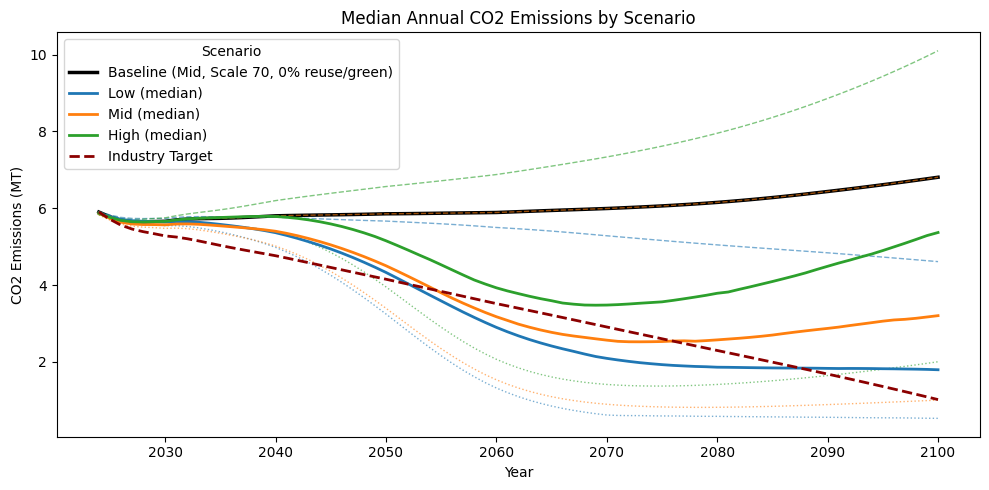

In [283]:
def get_baseline_emissions(df_qmc_mid, param_df, baseline_scale=70):
    """
    Pulls the annual carbon_emissions trajectory for the Mid scenario,
    at baseline_scale, with 0% reuse and 0% green steel ceilings.
    """
    baseline_draw = param_df[(param_df['B_reuse'] == 0.0) & (param_df['B_green'] == 0.0)]
    if baseline_draw.empty:
        raise ValueError("No draw found with B_reuse=0 and B_green=0 — check param_df.")
    baseline_draw_id = baseline_draw['draw_id'].iloc[0]

    baseline_rows = df_qmc_mid[
        (df_qmc_mid['scale'] == baseline_scale) &
        (df_qmc_mid['draw_id'] == baseline_draw_id)
    ].sort_values('year')

    return baseline_rows.set_index('year')['carbon_emissions']


def emissions_summary_by_year(df_qmc):
    """Median, min, and max carbon_emissions per year, across all scales and draws."""
    grouped = df_qmc.groupby('year')['carbon_emissions']
    return pd.DataFrame({
        'median': grouped.median(),
        'min': grouped.min(),
        'max': grouped.max(),
    })


def plot_emissions_comparison(df_qmc_low, df_qmc_mid, df_qmc_high, param_df,
                                industry_target=None,
                                baseline_scale=70,
                                title='Median Annual CO2 Emissions by Scenario'):
    summaries = {
        'Low':  emissions_summary_by_year(df_qmc_low) / 1e6,
        'Mid':  emissions_summary_by_year(df_qmc_mid)  / 1e6,
        'High': emissions_summary_by_year(df_qmc_high)  / 1e6,
    }

    baseline_series = get_baseline_emissions(df_qmc_mid, param_df, baseline_scale=baseline_scale)

    colors = {'Low': 'tab:blue', 'Mid': 'tab:orange', 'High': 'tab:green'}

    fig, ax = plt.subplots(figsize=(10, 5))

    # baseline: Mid scenario, scale 70, 0% reuse, 0% green steel
    ax.plot(baseline_series.index, baseline_series.values / 1e6,
            color='black', linewidth=2.5,
            label=f'Baseline (Mid, Scale {baseline_scale}, 0% reuse/green)', zorder=1)

    for label, summary in summaries.items():
        color = colors[label]
        ax.plot(summary.index, summary['median'], label=f'{label} (median)',
                linewidth=2, color=color, zorder=5)
        ax.plot(summary.index, summary['max'], linestyle='--', linewidth=1,
                color=color, alpha=0.6, zorder=3)
        ax.plot(summary.index, summary['min'], linestyle=':', linewidth=1,
                color=color, alpha=0.6, zorder=3)

    # industry target reference line
    if industry_target is not None:
        target_series = industry_target.set_index('year')['total_emissions_co2_MT'] / 1e6 \
            if 'year' in industry_target.columns else industry_target['total_emissions_co2_MT'] / 1e6
        ax.plot(target_series.index, target_series.values,
                color='darkred', linewidth=2, linestyle='--',
                label='Industry Target', zorder=8)

    ax.set_xlabel('Year')
    ax.set_ylabel('CO2 Emissions (MT)')
    ax.set_title(title)
    ax.legend(title='Scenario', loc='upper left')

    plt.tight_layout()
    plt.show()
    return fig, ax


fig, ax = plot_emissions_comparison(df_qmc_low, df_qmc_mid, df_qmc_high, param_df,
                                     industry_target=industry_target)

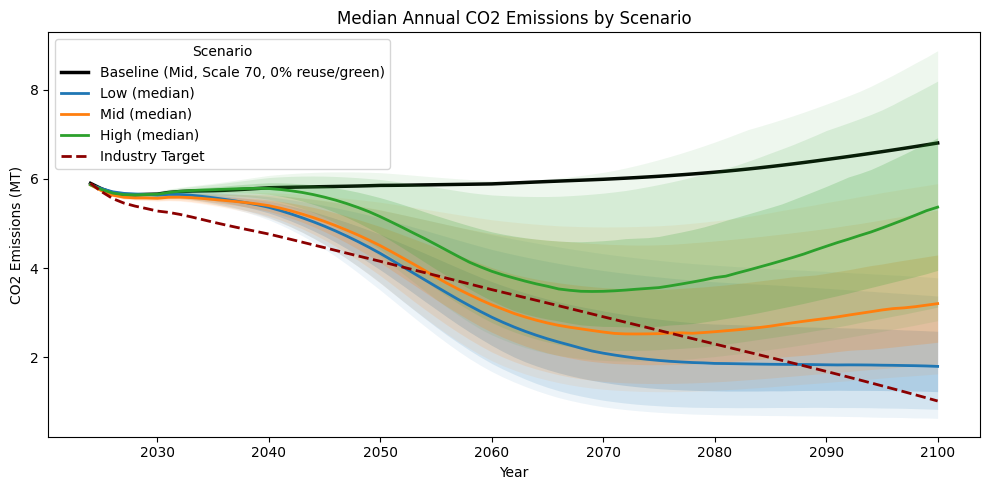

In [313]:
def get_baseline_emissions(df_qmc_mid, param_df, baseline_scale=70):
    baseline_draw = param_df[(param_df['B_reuse'] == 0.0) & (param_df['B_green'] == 0.0)]
    if baseline_draw.empty:
        raise ValueError("No draw found with B_reuse=0 and B_green=0 — check param_df.")
    baseline_draw_id = baseline_draw['draw_id'].iloc[0]

    baseline_rows = df_qmc_mid[
        (df_qmc_mid['scale'] == baseline_scale) &
        (df_qmc_mid['draw_id'] == baseline_draw_id)
    ].sort_values('year')

    return baseline_rows.set_index('year')['carbon_emissions']


def emissions_summary_by_year(df_qmc, quantiles=(0.05, 0.10, 0.25, 0.75, 0.90, 0.95)):
    grouped = df_qmc.groupby('year')['carbon_emissions']
    summary = pd.DataFrame({'median': grouped.median()})
    for q in quantiles:
        col_name = f'q{round(q*100)}'
        summary[col_name] = grouped.quantile(q)
    return summary


def plot_emissions_comparison(df_qmc_low, df_qmc_mid, df_qmc_high, param_df,
                                industry_target=None,
                                baseline_scale=70,
                                title='Median Annual CO2 Emissions by Scenario'):
    quantiles = (0.05, 0.10, 0.25, 0.75, 0.90, 0.95)
    summaries = {
        'Low':  emissions_summary_by_year(df_qmc_low, quantiles) / 1e6,
        'Mid':  emissions_summary_by_year(df_qmc_mid, quantiles) / 1e6,
        'High': emissions_summary_by_year(df_qmc_high, quantiles) / 1e6,
    }

    baseline_series = get_baseline_emissions(df_qmc_mid, param_df, baseline_scale=baseline_scale)

    colors = {'Low': 'tab:blue', 'Mid': 'tab:orange', 'High': 'tab:green'}

    band_pairs = [
        ('q5', 'q95', 0.08),
        ('q10', 'q90', 0.12),
        ('q25', 'q75', 0.20),
    ]

    fig, ax = plt.subplots(figsize=(10, 5))

    ax.plot(baseline_series.index, baseline_series.values / 1e6,
            color='black', linewidth=2.5,
            label=f'Baseline (Mid, Scale {baseline_scale}, 0% reuse/green)', zorder=1)

    for label, summary in summaries.items():
        color = colors[label]

        for lower_q, upper_q, alpha in band_pairs:
            ax.fill_between(summary.index, summary[lower_q], summary[upper_q],
                             color=color, alpha=alpha, zorder=2, linewidth=0)

        ax.plot(summary.index, summary['median'], label=f'{label} (median)',
                linewidth=2, color=color, zorder=5)

    if industry_target is not None:
        target_series = industry_target.set_index('year')['total_emissions_co2_MT'] / 1e6 \
            if 'year' in industry_target.columns else industry_target['total_emissions_co2_MT'] / 1e6
        ax.plot(target_series.index, target_series.values,
                color='darkred', linewidth=2, linestyle='--',
                label='Industry Target', zorder=8)

    ax.set_xlabel('Year')
    ax.set_ylabel('CO2 Emissions (MT)')
    ax.set_title(title)
    ax.legend(title='Scenario', loc='upper left')

    plt.tight_layout()
    plt.show()
    return fig, ax


fig, ax = plot_emissions_comparison(df_qmc_low, df_qmc_mid, df_qmc_high, param_df,
                                     industry_target=industry_target)

In [297]:
df_qmc_high

,scale,draw_id,year,reuse_rate,reused_outflow,production_demand,green_share,green_production,conventional_production,carbon_emissions,energy_usage
0,70,0,2024,0.000000,0.000000,5.821644,0.000000,0.000000,5.821644,5.907558e+06,96998.480534
1,70,0,2025,0.000000,0.000000,5.722451,0.000000,0.000000,5.722451,5.806901e+06,95345.757905
2,70,0,2026,0.000000,0.000000,5.650801,0.000000,0.000000,5.650801,5.734193e+06,94151.944375
3,70,0,2027,0.000000,0.000000,5.625290,0.000000,0.000000,5.625290,5.708306e+06,93726.886222
4,70,0,2028,0.000000,0.000000,5.629552,0.000000,0.000000,5.629552,5.712631e+06,93797.911125
...,...,...,...,...,...,...,...,...,...,...,...
381992,110,120,2096,0.997871,3.155799,6.264026,0.997871,6.250691,0.013336,2.475845e+06,124635.667358
381993,110,120,2097,0.998167,3.107231,6.440192,0.998167,6.428388,0.011804,2.528115e+06,127852.254955
381994,110,120,2098,0.998422,3.062130,6.616677,0.998422,6.606236,0.010441,2.581013e+06,131081.876907
381995,110,120,2099,0.998641,3.020729,6.793330,0.998641,6.784101,0.009229,2.634501e+06,134322.211316


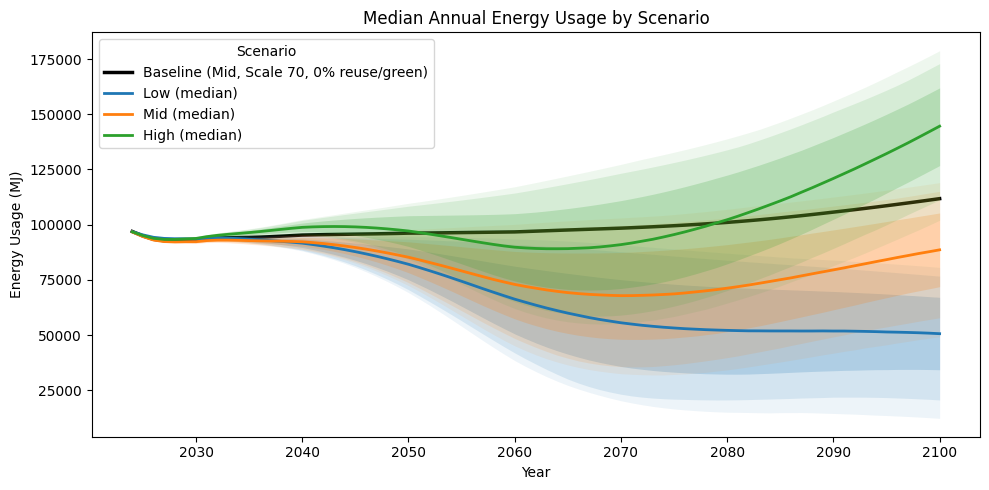

In [316]:
def get_baseline_energy(df_qmc_mid, param_df, baseline_scale=70, energy_col='energy_usage'):
    """
    Pulls the annual energy usage trajectory for the Mid scenario,
    at baseline_scale, with 0% reuse and 0% green steel ceilings.
    """
    baseline_draw = param_df[(param_df['B_reuse'] == 0.0) & (param_df['B_green'] == 0.0)]
    if baseline_draw.empty:
        raise ValueError("No draw found with B_reuse=0 and B_green=0 — check param_df.")
    baseline_draw_id = baseline_draw['draw_id'].iloc[0]

    baseline_rows = df_qmc_mid[
        (df_qmc_mid['scale'] == baseline_scale) &
        (df_qmc_mid['draw_id'] == baseline_draw_id)
    ].sort_values('year')

    return baseline_rows.set_index('year')[energy_col]


def energy_summary_by_year(df_qmc, energy_col='energy_usage', quantiles=(0.05, 0.10, 0.25, 0.75, 0.90, 0.95)):
    """
    Median plus a set of quantiles per year, across all scales and draws —
    used to build density-style shaded bands.
    """
    grouped = df_qmc.groupby('year')[energy_col]
    summary = pd.DataFrame({'median': grouped.median()})
    for q in quantiles:
        col_name = f'q{round(q*100)}'
        summary[col_name] = grouped.quantile(q)
    return summary


def plot_energy_comparison(df_qmc_low, df_qmc_mid, df_qmc_high, param_df,
                             energy_col='energy_usage',
                             baseline_scale=70,
                             title='Median Annual Energy Usage by Scenario'):
    quantiles = (0.05, 0.10, 0.25, 0.75, 0.90, 0.95)
    summaries = {
        'Low':  energy_summary_by_year(df_qmc_low, energy_col=energy_col, quantiles=quantiles),
        'Mid':  energy_summary_by_year(df_qmc_mid, energy_col=energy_col, quantiles=quantiles),
        'High': energy_summary_by_year(df_qmc_high, energy_col=energy_col, quantiles=quantiles),
    }

    baseline_series = get_baseline_energy(df_qmc_mid, param_df, baseline_scale=baseline_scale,
                                            energy_col=energy_col)

    colors = {'Low': 'tab:blue', 'Mid': 'tab:orange', 'High': 'tab:green'}

    band_pairs = [
        ('q5', 'q95', 0.08),
        ('q10', 'q90', 0.12),
        ('q25', 'q75', 0.20),
    ]

    fig, ax = plt.subplots(figsize=(10, 5))

    # baseline: Mid scenario, scale 70, 0% reuse, 0% green steel
    ax.plot(baseline_series.index, baseline_series.values,
            color='black', linewidth=2.5,
            label=f'Baseline (Mid, Scale {baseline_scale}, 0% reuse/green)', zorder=1)

    for label, summary in summaries.items():
        color = colors[label]

        for lower_q, upper_q, alpha in band_pairs:
            ax.fill_between(summary.index, summary[lower_q], summary[upper_q],
                             color=color, alpha=alpha, zorder=2, linewidth=0)

        ax.plot(summary.index, summary['median'], label=f'{label} (median)',
                linewidth=2, color=color, zorder=5)

    ax.set_xlabel('Year')
    ax.set_ylabel('Energy Usage (MJ)')
    ax.set_title(title)
    ax.legend(title='Scenario', loc='upper left')

    plt.tight_layout()
    plt.show()
    return fig, ax


fig, ax = plot_energy_comparison(df_qmc_low, df_qmc_mid, df_qmc_high, param_df)

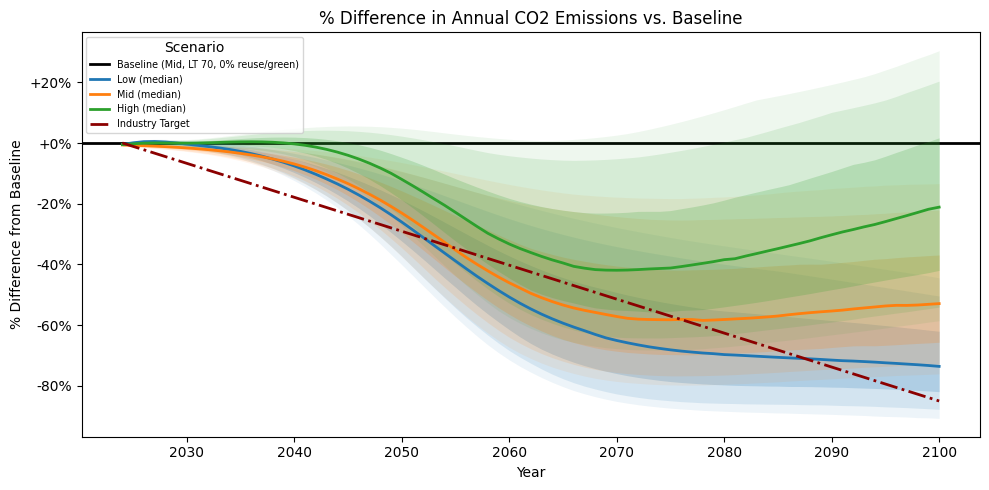

In [315]:
def emissions_summary_by_year(df_qmc, quantiles=(0.05, 0.10, 0.25, 0.75, 0.90, 0.95)):
    """
    Median plus a set of quantiles per year, across all scales and draws —
    used to build density-style shaded bands.
    """
    grouped = df_qmc.groupby('year')['carbon_emissions']
    summary = pd.DataFrame({'median': grouped.median()})
    for q in quantiles:
        col_name = f'q{round(q*100)}'
        summary[col_name] = grouped.quantile(q)
    return summary


def compute_pct_diff_from_baseline(summary, baseline_series):
    """
    Converts an emissions summary (median + quantile columns by year) into
    % difference from a baseline series (indexed by year).
    """
    aligned_baseline = baseline_series.reindex(summary.index)
    pct_diff = pd.DataFrame(index=summary.index)
    for col in summary.columns:
        pct_diff[col] = (summary[col] - aligned_baseline) / aligned_baseline * 100
    return pct_diff


def compute_pct_diff_series_from_baseline(series, baseline_series):
    """
    Same logic as compute_pct_diff_from_baseline, but for a single series
    (not a summary) — used for reference lines like industry targets or
    external emissions estimates.
    """
    aligned_baseline = baseline_series.reindex(series.index)
    return (series - aligned_baseline) / aligned_baseline * 100


def plot_emissions_comparison(df_qmc_low, df_qmc_mid, df_qmc_high, param_df,
                                industry_target=None, arehart=None,
                                baseline_scale=70,
                                title='% Difference in Annual CO2 Emissions vs. Baseline'):
    # identify the baseline draw_id: the grid point where B_reuse=0 and B_green=0
    baseline_draw = param_df[(param_df['B_reuse'] == 0.0) & (param_df['B_green'] == 0.0)]
    if baseline_draw.empty:
        raise ValueError("No draw found with B_reuse=0 and B_green=0 — check param_df.")
    baseline_draw_id = baseline_draw['draw_id'].iloc[0]

    baseline_rows = df_qmc_mid[
        (df_qmc_mid['scale'] == baseline_scale) &
        (df_qmc_mid['draw_id'] == baseline_draw_id)
    ].sort_values('year')
    baseline_series = baseline_rows.set_index('year')['carbon_emissions']

    quantiles = (0.05, 0.10, 0.25, 0.75, 0.90, 0.95)
    summaries = {
        'Low':  emissions_summary_by_year(df_qmc_low, quantiles),
        'Mid':  emissions_summary_by_year(df_qmc_mid, quantiles),
        'High': emissions_summary_by_year(df_qmc_high, quantiles),
    }

    pct_summaries = {label: compute_pct_diff_from_baseline(s, baseline_series)
                      for label, s in summaries.items()}

    colors = {'Low': 'tab:blue', 'Mid': 'tab:orange', 'High': 'tab:green'}

    band_pairs = [
        ('q5', 'q95', 0.08),
        ('q10', 'q90', 0.12),
        ('q25', 'q75', 0.20),
    ]

    fig, ax = plt.subplots(figsize=(10, 5))

    # baseline itself: flat 0% line, in black
    ax.axhline(0, color='black', linewidth=2, label='Baseline (Mid, LT 70, 0% reuse/green)', zorder=1)

    for label, pct_summary in pct_summaries.items():
        color = colors[label]

        for lower_q, upper_q, alpha in band_pairs:
            ax.fill_between(pct_summary.index, pct_summary[lower_q], pct_summary[upper_q],
                             color=color, alpha=alpha, zorder=2, linewidth=0)

        ax.plot(pct_summary.index, pct_summary['median'], label=f'{label} (median)',
                linewidth=2, color=color, zorder=5)

    # --- industry target reference line ---
    if industry_target is not None:
        target_series = industry_target.set_index('year')['total_emissions_co2_MT'] \
            if 'year' in industry_target.columns else industry_target['total_emissions_co2_MT']
        pct_target = compute_pct_diff_series_from_baseline(target_series, baseline_series)
        ax.plot(pct_target.index, pct_target.values, label='Industry Target',
                color='darkred', linewidth=2, linestyle='-.', zorder=15)

    # --- Arehart reference line ---
    if arehart is not None:
        arehart_series = arehart.set_index('year')['annual_emissions'] \
            if 'year' in arehart.columns else arehart['annual_emissions']
        pct_arehart = compute_pct_diff_series_from_baseline(arehart_series, baseline_series)
        ax.plot(pct_arehart.index, pct_arehart.values, label='Arehart Emissions',
                color='purple', linewidth=2, linestyle='-.', zorder=8)

    ax.set_xlabel('Year')
    ax.set_ylabel('% Difference from Baseline')
    ax.set_title(title)
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:+.0f}%'))
    ax.legend(title='Scenario', loc='upper left', fontsize="x-small")

    plt.tight_layout()
    plt.show()
    return fig, ax


fig, ax = plot_emissions_comparison(
    df_qmc_low, df_qmc_mid, df_qmc_high, param_df,
    industry_target=industry_target
)

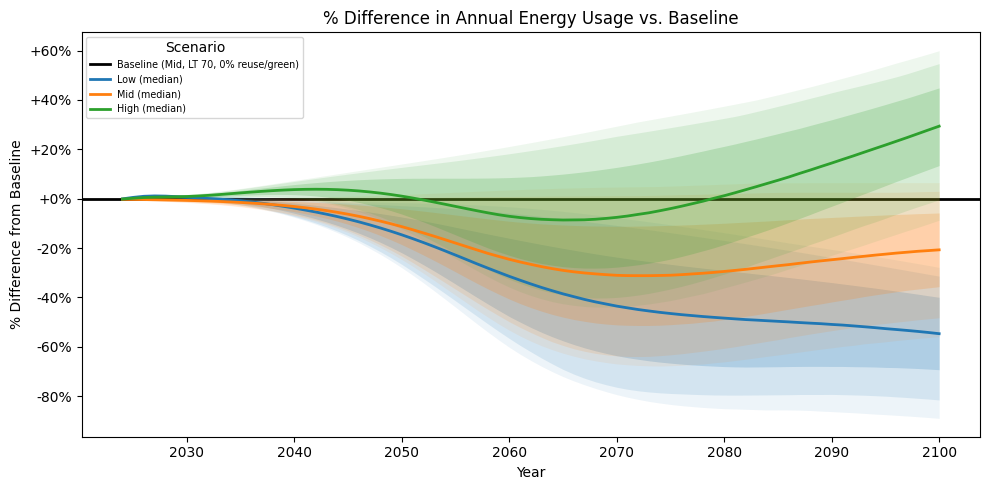

In [317]:
def compute_pct_diff_from_baseline(summary, baseline_series):
    """
    Converts a summary (median + quantile columns by year) into % difference
    from a baseline series (indexed by year). Works for any metric.
    """
    aligned_baseline = baseline_series.reindex(summary.index)
    pct_diff = pd.DataFrame(index=summary.index)
    for col in summary.columns:
        pct_diff[col] = (summary[col] - aligned_baseline) / aligned_baseline * 100
    return pct_diff


def plot_energy_pct_comparison(df_qmc_low, df_qmc_mid, df_qmc_high, param_df,
                                 energy_col='energy_usage',
                                 baseline_scale=70,
                                 title='% Difference in Annual Energy Usage vs. Baseline'):
    baseline_series = get_baseline_energy(df_qmc_mid, param_df, baseline_scale=baseline_scale,
                                            energy_col=energy_col)

    quantiles = (0.05, 0.10, 0.25, 0.75, 0.90, 0.95)
    summaries = {
        'Low':  energy_summary_by_year(df_qmc_low, energy_col=energy_col, quantiles=quantiles),
        'Mid':  energy_summary_by_year(df_qmc_mid, energy_col=energy_col, quantiles=quantiles),
        'High': energy_summary_by_year(df_qmc_high, energy_col=energy_col, quantiles=quantiles),
    }

    pct_summaries = {label: compute_pct_diff_from_baseline(s, baseline_series)
                      for label, s in summaries.items()}

    colors = {'Low': 'tab:blue', 'Mid': 'tab:orange', 'High': 'tab:green'}

    band_pairs = [
        ('q5', 'q95', 0.08),
        ('q10', 'q90', 0.12),
        ('q25', 'q75', 0.20),
    ]

    fig, ax = plt.subplots(figsize=(10, 5))

    # baseline itself: flat 0% line, in black
    ax.axhline(0, color='black', linewidth=2, label=f'Baseline (Mid, LT {baseline_scale}, 0% reuse/green)', zorder=1)

    for label, pct_summary in pct_summaries.items():
        color = colors[label]

        for lower_q, upper_q, alpha in band_pairs:
            ax.fill_between(pct_summary.index, pct_summary[lower_q], pct_summary[upper_q],
                             color=color, alpha=alpha, zorder=2, linewidth=0)

        ax.plot(pct_summary.index, pct_summary['median'], label=f'{label} (median)',
                linewidth=2, color=color, zorder=5)

    ax.set_xlabel('Year')
    ax.set_ylabel('% Difference from Baseline')
    ax.set_title(title)
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:+.0f}%'))
    ax.legend(title='Scenario', loc='upper left', fontsize='x-small')

    plt.tight_layout()
    plt.show()
    return fig, ax


fig, ax = plot_energy_pct_comparison(df_qmc_low, df_qmc_mid, df_qmc_high, param_df)

In [287]:
### Cumulative Emissions

def summarize_lifetime_emissions(df_qmc, param_df, scenario_label):
    """
    Collapses a QMC results DataFrame (year-level) into one row per
    (scale, draw_id) with cumulative lifetime emissions, joined against
    that draw's reuse/green ceiling parameters.
    """
    cumulative = (
        df_qmc.groupby(['scale', 'draw_id'])['carbon_emissions']
        .sum()
        .reset_index()
        .rename(columns={'carbon_emissions': 'cumulative_emissions'})
    )

    # bring in B_reuse / B_green (the ceilings) for each draw_id
    cumulative = cumulative.merge(
        param_df[['draw_id', 'B_reuse', 'B_green']],
        on='draw_id',
        how='left'
    )

    cumulative['scenario'] = scenario_label
    return cumulative

In [288]:
df_lifetime_low  = summarize_lifetime_emissions(df_qmc_low,  param_df, 'Low')
df_lifetime_mid  = summarize_lifetime_emissions(df_qmc_mid,  param_df, 'Mid')
df_lifetime_high = summarize_lifetime_emissions(df_qmc_high, param_df, 'High')

df_lifetime_emissions = pd.concat(
    [df_lifetime_low, df_lifetime_mid, df_lifetime_high],
    ignore_index=True
)

print(df_lifetime_emissions.shape)  # should be (63000, 6)
df_lifetime_emissions.head()

(14883, 6)


,scale,draw_id,cumulative_emissions,B_reuse,B_green,scenario
0,70,0,4.129988e+08,0.0,0.0,Low
1,70,1,3.973725e+08,0.0,0.1,Low
2,70,2,3.817461e+08,0.0,0.2,Low
3,70,3,3.661197e+08,0.0,0.3,Low
4,70,4,3.504933e+08,0.0,0.4,Low


In [318]:
def summarize_lifetime_energy(df_qmc, param_df, scenario_label, energy_col='energy_usage'):
    """
    Collapses a QMC results DataFrame (year-level) into one row per
    (scale, draw_id) with cumulative lifetime electricity usage, joined
    against that draw's reuse/green ceiling parameters.
    """
    cumulative = (
        df_qmc.groupby(['scale', 'draw_id'])[energy_col]
        .sum()
        .reset_index()
        .rename(columns={energy_col: 'cumulative_energy'})
    )

    cumulative = cumulative.merge(
        param_df[['draw_id', 'B_reuse', 'B_green']],
        on='draw_id',
        how='left'
    )

    cumulative['scenario'] = scenario_label
    return cumulative


df_lifetime_energy_low  = summarize_lifetime_energy(df_qmc_low,  param_df, 'Low')
df_lifetime_energy_mid  = summarize_lifetime_energy(df_qmc_mid,  param_df, 'Mid')
df_lifetime_energy_high = summarize_lifetime_energy(df_qmc_high, param_df, 'High')

df_lifetime_energy = pd.concat(
    [df_lifetime_energy_low, df_lifetime_energy_mid, df_lifetime_energy_high],
    ignore_index=True
)

print(df_lifetime_energy.shape)

(14883, 6)


In [289]:
def plot_parallel_coordinates(df_lifetime, scenario_label, title=None,
                                axes_cols=('scale', 'B_reuse', 'B_green'),
                                axes_labels=('Building Lifespan', 'Reuse %', 'Green Steel %'),
                                color_col='cumulative_emissions',
                                color_label='Cumulative Emissions',
                                cmap='viridis', alpha=0.4, sample_n=None, seed=42):
    """
    Custom parallel coordinates plot for continuous variables, colored by
    color_col (not plotted as its own axis). Optionally samples a subset
    of rows for readability.
    """
    subset = df_lifetime[df_lifetime['scenario'] == scenario_label].copy()

    if sample_n is not None and sample_n < len(subset):
        subset = subset.sample(n=sample_n, random_state=seed)

    n_axes = len(axes_cols)
    x_positions = np.arange(n_axes)

    normed = pd.DataFrame(index=subset.index)
    col_ranges = {}
    for col in axes_cols:
        vmin, vmax = subset[col].min(), subset[col].max()
        col_ranges[col] = (vmin, vmax)
        normed[col] = (subset[col] - vmin) / (vmax - vmin) if vmax > vmin else 0.5

    norm = mcolors.Normalize(vmin=subset[color_col].min(), vmax=subset[color_col].max())
    colormap = cm.get_cmap(cmap)

    fig, ax = plt.subplots(figsize=(9, 6))

    for idx in normed.index:
        y_values = [normed.loc[idx, col] for col in axes_cols]
        color = colormap(norm(subset.loc[idx, color_col]))
        ax.plot(x_positions, y_values, color=color, alpha=alpha, linewidth=1)

    for x in x_positions:
        ax.axvline(x, color='gray', linewidth=0.8, zorder=0)

    ax.set_xticks(x_positions)
    ax.tick_params(axis='x', pad=15)
    ax.set_xticklabels(axes_labels)
    ax.set_yticks([])

    for x, col in zip(x_positions, axes_cols):
        vmin, vmax = col_ranges[col]
        ax.text(x, 1.02, f'{vmax:.2g}', ha='center', va='bottom', fontsize=8, transform=ax.get_xaxis_transform())
        ax.text(x, -0.02, f'{vmin:.2g}', ha='center', va='top', fontsize=8, transform=ax.get_xaxis_transform())

    n_shown = len(subset)
    ax.set_title(title or f'Parallel Coordinates — {scenario_label} Scenario (n={n_shown})', pad=20)
    ax.set_ylim(-0.05, 1.05)

    sm = cm.ScalarMappable(cmap=colormap, norm=norm)
    sm.set_array([])
    cbar = fig.colorbar(sm, ax=ax, pad=0.02)
    cbar.set_label(color_label)

    plt.tight_layout()
    plt.show()
    return fig, ax



In [290]:
df_lifetime_emissions

,scale,draw_id,cumulative_emissions,B_reuse,B_green,scenario
0,70,0,4.129988e+08,0.0,0.0,Low
1,70,1,3.973725e+08,0.0,0.1,Low
2,70,2,3.817461e+08,0.0,0.2,Low
3,70,3,3.661197e+08,0.0,0.3,Low
4,70,4,3.504933e+08,0.0,0.4,Low
...,...,...,...,...,...,...
14878,110,116,3.031915e+08,1.0,0.6,High
14879,110,117,2.900067e+08,1.0,0.7,High
14880,110,118,2.768219e+08,1.0,0.8,High
14881,110,119,2.636371e+08,1.0,0.9,High


C:\Users\aorga\AppData\Local\Temp\ipykernel_38548\639559421.py:28: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  colormap = cm.get_cmap(cmap)


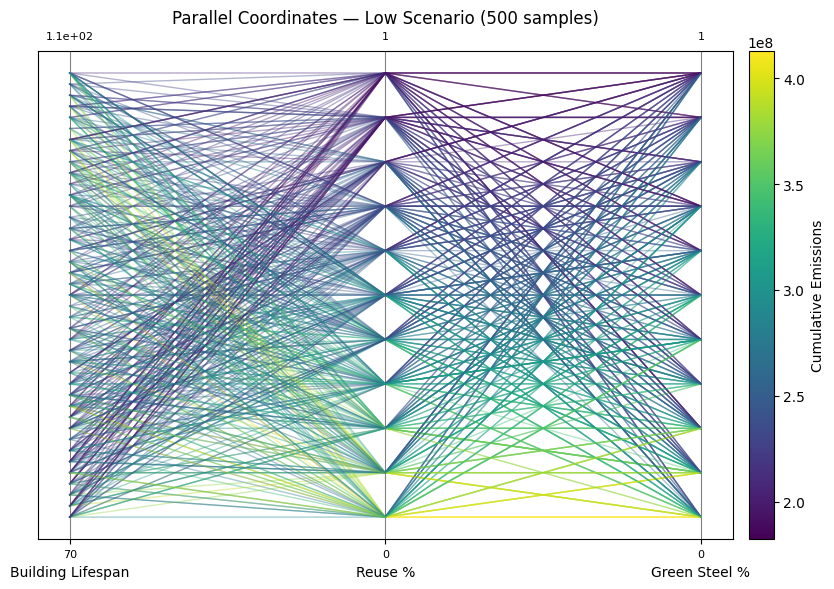

C:\Users\aorga\AppData\Local\Temp\ipykernel_38548\639559421.py:28: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  colormap = cm.get_cmap(cmap)


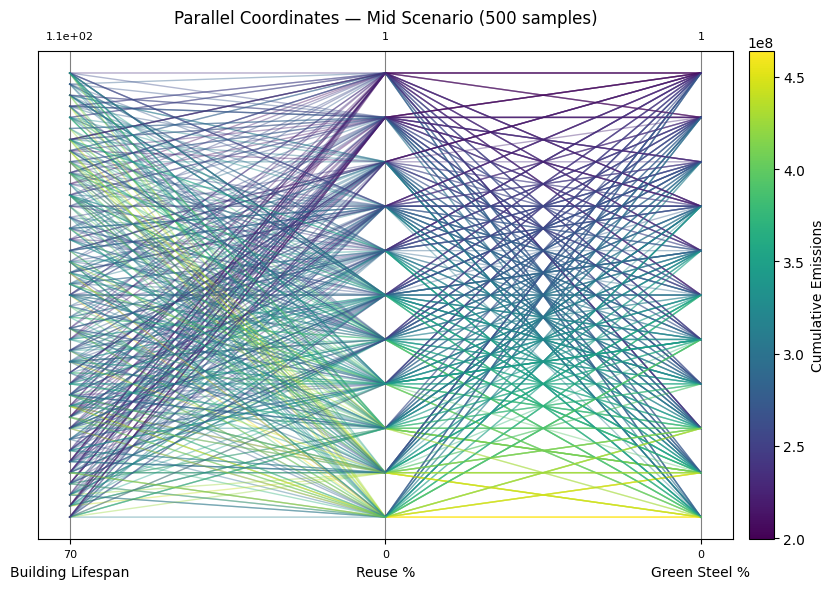

C:\Users\aorga\AppData\Local\Temp\ipykernel_38548\639559421.py:28: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  colormap = cm.get_cmap(cmap)


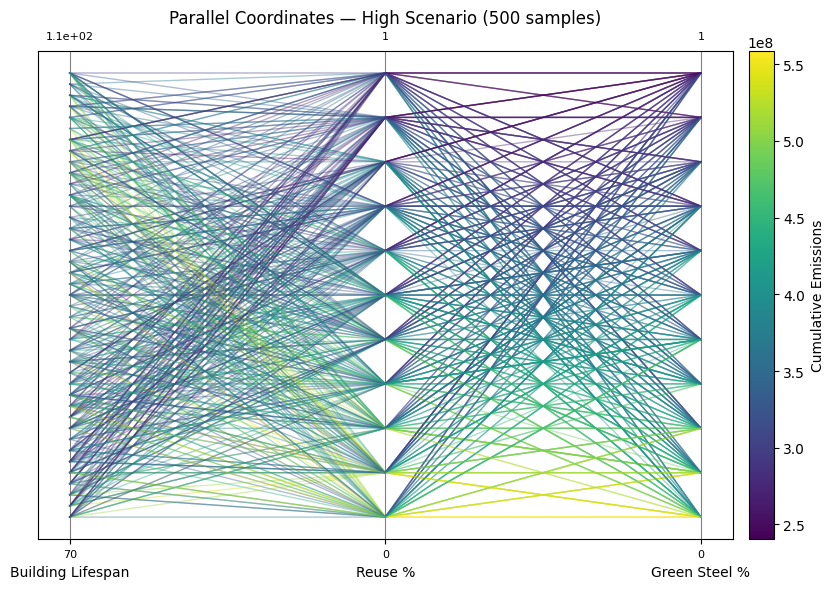

In [291]:

fig_low, ax_low = plot_parallel_coordinates(df_lifetime_emissions, 'Low', sample_n=500,
                                              title='Parallel Coordinates — Low Scenario (500 samples)')
fig_mid, ax_mid = plot_parallel_coordinates(df_lifetime_emissions, 'Mid', sample_n=500,
                                              title='Parallel Coordinates — Mid Scenario (500 samples)')
fig_high, ax_high = plot_parallel_coordinates(df_lifetime_emissions, 'High', sample_n=500,
                                                title='Parallel Coordinates — High Scenario (500 samples)')


In [292]:
def plot_emissions_bubble(df_lifetime, scenario_label, title=None,
                            x_col='B_reuse', y_col='B_green', color_col='scale',
                            size_col='cumulative_emissions', cmap='viridis',
                            size_range=(20, 800), alpha=0.3):
    """
    Scatter/bubble chart: x = reuse %, y = green steel %, color = lifespan scale,
    bubble size = cumulative lifetime emissions.
    """
    subset = df_lifetime[df_lifetime['scenario'] == scenario_label].copy()

    # scale bubble sizes: normalize emissions to the desired pixel-area range
    emissions = subset[size_col].values
    e_min, e_max = emissions.min(), emissions.max()
    if e_max > e_min:
        sizes = size_range[0] + (emissions - e_min) / (e_max - e_min) * (size_range[1] - size_range[0])
    else:
        sizes = np.full_like(emissions, size_range[0], dtype=float)

    fig, ax = plt.subplots(figsize=(8, 7))

    sc = ax.scatter(
        subset[x_col] * 100,  # convert 0-1 ceiling to percent for readability
        subset[y_col] * 100,
        c=subset[color_col],
        s=sizes,
        cmap=cmap,
        alpha=alpha,
        edgecolors='white',
        linewidths=0.5,
    )

    ax.set_xlabel('Reuse Ceiling (%)')
    ax.set_ylabel('Green Steel Ceiling (%)')
    ax.set_title(title or f'Reuse vs. Green Steel Ceiling — {scenario_label} Scenario')

    cbar = fig.colorbar(sc, ax=ax, pad=0.02)
    cbar.set_label('Building Lifespan (scale)')

    # bubble-size legend: a few reference sizes
    legend_emissions = np.linspace(e_min, e_max, 4)
    legend_sizes = size_range[0] + (legend_emissions - e_min) / (e_max - e_min) * (size_range[1] - size_range[0])
    legend_handles = [
        plt.scatter([], [], s=s, color='gray', alpha=0.5, edgecolors='white')
        for s in legend_sizes
    ]
    legend_labels = [f'{e:,.0f}' for e in legend_emissions]
    ax.legend(legend_handles, legend_labels, title='Cumulative\nEmissions', loc='upper left',
              bbox_to_anchor=(1.25, 1), frameon=False)

    plt.tight_layout()
    plt.show()
    return fig, ax


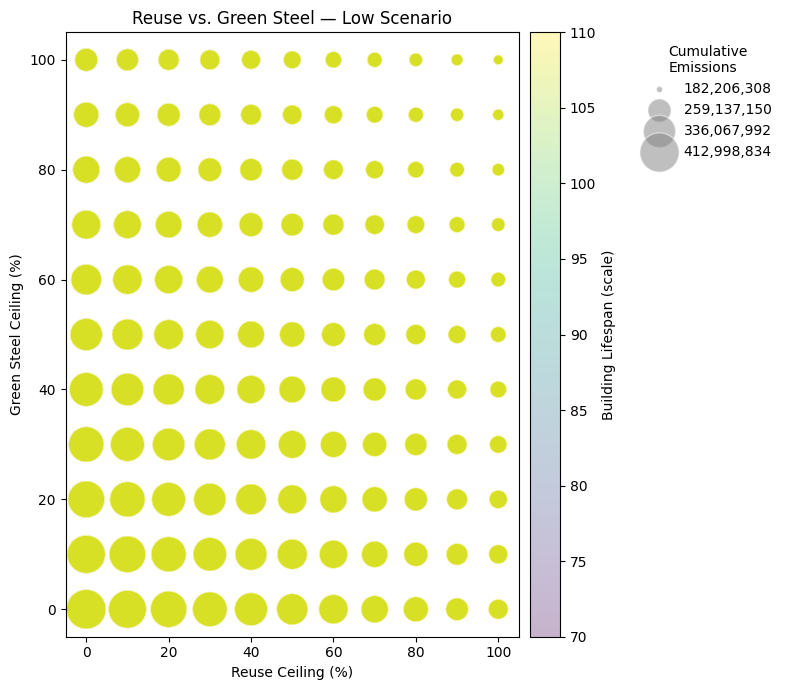

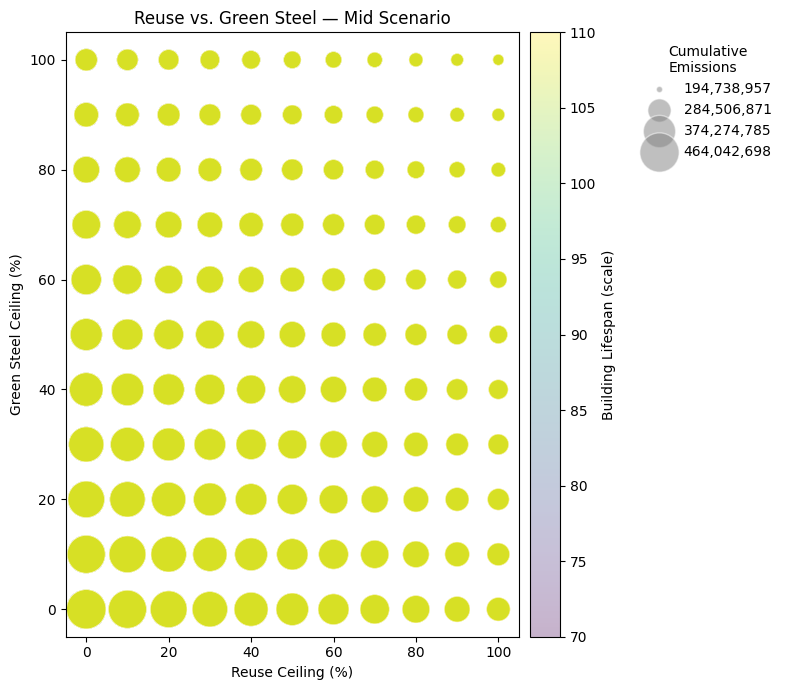

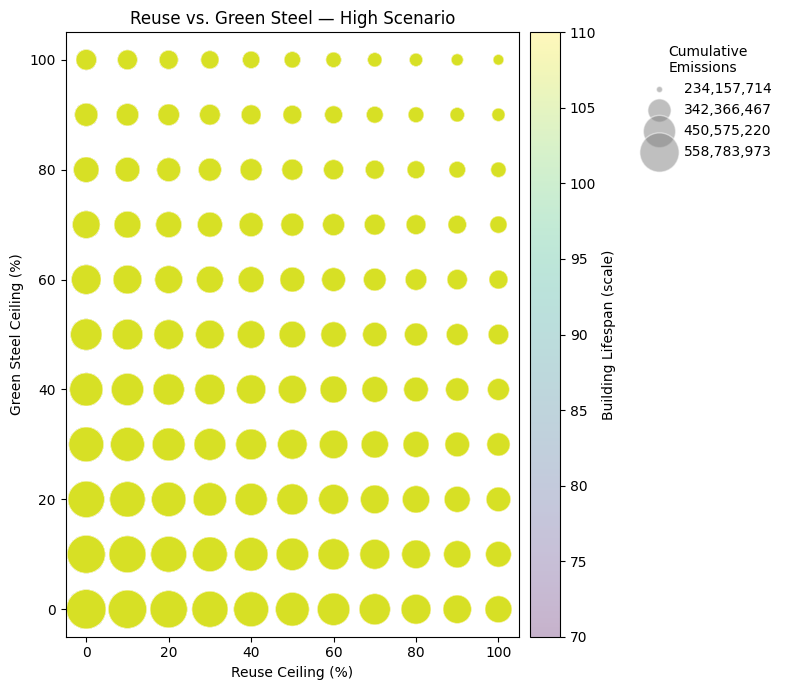

In [293]:
fig_low, ax_low = plot_emissions_bubble(df_lifetime_emissions, 'Low', title='Reuse vs. Green Steel — Low Scenario')
fig_mid, ax_mid = plot_emissions_bubble(df_lifetime_emissions, 'Mid', title='Reuse vs. Green Steel — Mid Scenario')
fig_high, ax_high = plot_emissions_bubble(df_lifetime_emissions, 'High', title='Reuse vs. Green Steel — High Scenario')

In [294]:
def plot_emissions_bubble_grid(df_lifetime, scenario_label, title=None,
                                 x_col='B_reuse', y_col='B_green', size_col='cumulative_emissions',
                                 cmap='viridis', size_range=(10, 200), alpha=0.6,
                                 nrows=3, ncols=7):
    """
    Grid of bubble scatter plots, one subplot per scale, for a single scenario.
    x = reuse %, y = green steel %, bubble size = cumulative emissions.
    Color is fixed per scale (not needed as a channel since each panel = one scale),
    but we still color by emissions to make the size redundant/reinforcing.
    """
    subset = df_lifetime[df_lifetime['scenario'] == scenario_label].copy()
    scales = sorted(subset['scale'].unique())

    # shared color/size scaling across all panels so panels are comparable
    e_min, e_max = subset[size_col].min(), subset[size_col].max()
    norm = plt.Normalize(vmin=e_min, vmax=e_max)
    colormap = cm.get_cmap(cmap)

    fig, axes = plt.subplots(nrows, ncols, figsize=(3 * ncols, 3 * nrows),
                              sharex=True, sharey=True)
    axes = np.atleast_1d(axes).ravel()

    for idx, scale in enumerate(scales):
        ax = axes[idx]
        scale_data = subset[subset['scale'] == scale]

        emissions = scale_data[size_col].values
        if e_max > e_min:
            sizes = size_range[0] + (emissions - e_min) / (e_max - e_min) * (size_range[1] - size_range[0])
        else:
            sizes = np.full_like(emissions, size_range[0], dtype=float)

        sc = ax.scatter(
            scale_data[x_col] * 100,
            scale_data[y_col] * 100,
            c=emissions,
            s=sizes,
            cmap=cmap,
            norm=norm,
            alpha=alpha,
            edgecolors='white',
            linewidths=0.3,
        )
        ax.set_title(f'Scale {int(scale)}', fontsize=9)

    for idx in range(len(scales), len(axes)):
        axes[idx].axis('off')

    fig.suptitle(title or f'Reuse vs. Green Steel by Scale — {scenario_label} Scenario', fontsize=14)
    fig.supxlabel('Reuse Ceiling (%)')
    fig.supylabel('Green Steel Ceiling (%)')

    # shared colorbar
    sm = cm.ScalarMappable(cmap=colormap, norm=norm)
    sm.set_array([])
    cbar = fig.colorbar(sm, ax=axes, pad=0.01, shrink=0.6)
    cbar.set_label('Cumulative Emissions')

    plt.show()
    return fig, axes



C:\Users\aorga\AppData\Local\Temp\ipykernel_38548\3120914372.py:17: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  colormap = cm.get_cmap(cmap)


IndexError: index 21 is out of bounds for axis 0 with size 21

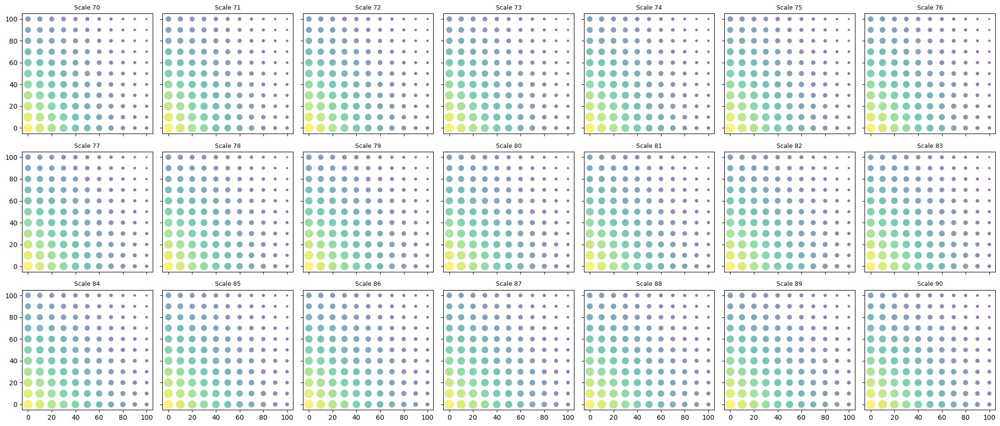

In [295]:

fig_low, axes_low = plot_emissions_bubble_grid(df_lifetime_emissions, 'Low', title='Reuse vs. Green Steel by Scale — Low Scenario')
fig_mid, axes_mid = plot_emissions_bubble_grid(df_lifetime_emissions, 'Mid', title='Reuse vs. Green Steel by Scale — Mid Scenario')
fig_high, axes_high = plot_emissions_bubble_grid(df_lifetime_emissions, 'High', title='Reuse vs. Green Steel by Scale — High Scenario')

In [296]:
def compute_relative_to_scale(df_lifetime, scenario_label, reference_scale=70):
    """
    For a given scenario, computes % difference in cumulative_emissions
    at each scale, relative to the same (B_reuse, B_green) combination
    at the reference_scale.
    """
    subset = df_lifetime[df_lifetime['scenario'] == scenario_label].copy()

    ref = subset[subset['scale'] == reference_scale][['B_reuse', 'B_green', 'cumulative_emissions']]
    ref = ref.rename(columns={'cumulative_emissions': 'ref_emissions'})

    merged = subset.merge(ref, on=['B_reuse', 'B_green'])
    merged['pct_diff_from_ref'] = (
        (merged['cumulative_emissions'] - merged['ref_emissions']) / merged['ref_emissions'] * 100
    )
    return merged


def plot_relative_emissions_bubble_grid(df_lifetime, scenario_label, reference_scale=70, title=None,
                                          x_col='B_reuse', y_col='B_green',
                                          size_col='pct_diff_from_ref',
                                          cmap='RdBu_r', size_range=(10, 200), alpha=0.6,
                                          nrows=3, ncols=7):
    """
    Grid of bubble scatter plots, one subplot per scale, showing % difference
    in cumulative emissions relative to reference_scale at the same
    (reuse%, green%) point. Diverging colormap centered at 0%.
    """
    merged = compute_relative_to_scale(df_lifetime, scenario_label, reference_scale)
    scales = sorted(merged['scale'].unique())

    # symmetric range around 0 so the diverging colormap is centered correctly
    abs_max = merged[size_col].abs().max()
    norm = mcolors.TwoSlopeNorm(vmin=-abs_max, vcenter=0, vmax=abs_max)
    colormap = cm.get_cmap(cmap)

    # size uses absolute magnitude of difference (bigger bubble = bigger deviation, either direction)
    abs_vals = merged[size_col].abs().values
    a_min, a_max = abs_vals.min(), abs_vals.max()

    fig, axes = plt.subplots(nrows, ncols, figsize=(3 * ncols, 3 * nrows),
                              sharex=True, sharey=True)
    axes = np.atleast_1d(axes).ravel()

    for idx, scale in enumerate(scales):
        ax = axes[idx]
        scale_data = merged[merged['scale'] == scale]

        abs_diff = scale_data[size_col].abs().values
        if a_max > a_min:
            sizes = size_range[0] + (abs_diff - a_min) / (a_max - a_min) * (size_range[1] - size_range[0])
        else:
            sizes = np.full_like(abs_diff, size_range[0], dtype=float)

        sc = ax.scatter(
            scale_data[x_col] * 100,
            scale_data[y_col] * 100,
            c=scale_data[size_col],
            s=sizes,
            cmap=cmap,
            norm=norm,
            alpha=alpha,
            edgecolors='white',
            linewidths=0.3,
        )
        label = f'{int(scale)}'
        if scale == reference_scale:
            label += ' (ref)'
        ax.set_title(label, fontsize=9)

    for idx in range(len(scales), len(axes)):
        axes[idx].axis('off')

    fig.suptitle(title or f'% Difference in Emissions vs. Lifespan {reference_scale} — {scenario_label} Scenario',
                 fontsize=14)
    fig.supxlabel('Reuse Ceiling (%)')
    fig.supylabel('Green Steel Ceiling (%)')

    fig.subplots_adjust(right=0.90, top=0.90, wspace=0.15, hspace=0.35)

    # dedicated axes for the colorbar: [left, bottom, width, height] in figure fraction coords
    cbar_ax = fig.add_axes([1, 0.15, 0.015, 0.7])

    sm = cm.ScalarMappable(cmap=colormap, norm=norm)
    sm.set_array([])
    cbar = fig.colorbar(sm, cax=cbar_ax)
    cbar.set_label(f'% Diff vs. lifespan {reference_scale}')
    
    plt.show()
    return fig, axes

C:\Users\aorga\AppData\Local\Temp\ipykernel_38548\111448421.py:35: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  colormap = cm.get_cmap(cmap)
c:\Users\aorga\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.canvas.print_figure(bytes_io, **kw)


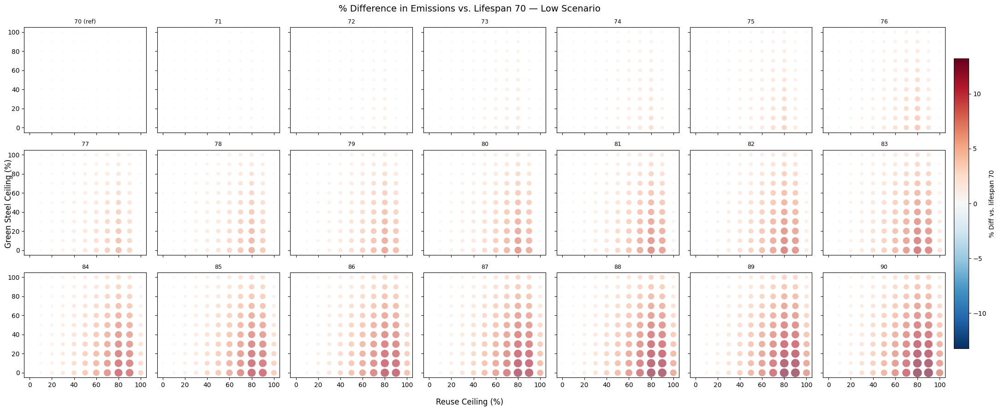

C:\Users\aorga\AppData\Local\Temp\ipykernel_38548\111448421.py:35: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  colormap = cm.get_cmap(cmap)
c:\Users\aorga\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.canvas.print_figure(bytes_io, **kw)


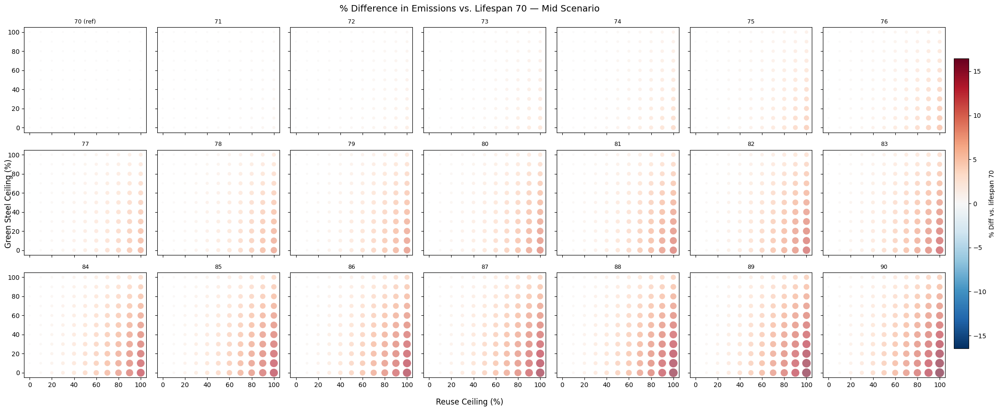

C:\Users\aorga\AppData\Local\Temp\ipykernel_38548\111448421.py:35: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  colormap = cm.get_cmap(cmap)
c:\Users\aorga\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.canvas.print_figure(bytes_io, **kw)


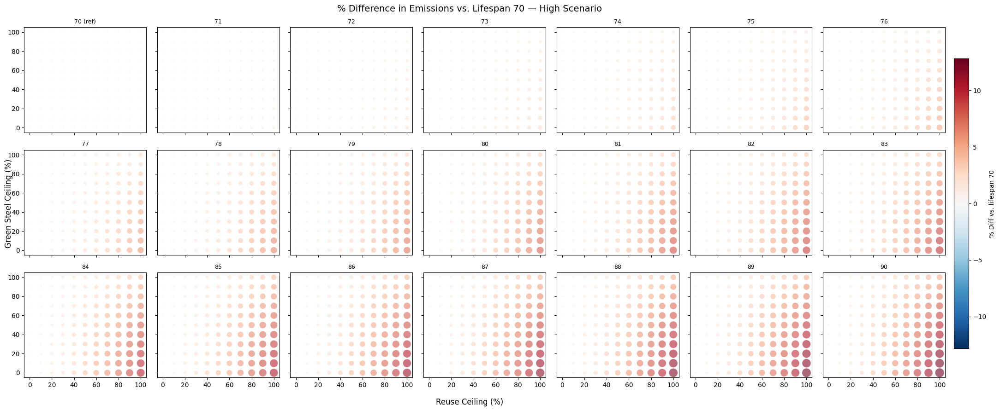

In [ ]:
fig_low, axes_low = plot_relative_emissions_bubble_grid(df_lifetime_emissions, 'Low')
fig_mid, axes_mid = plot_relative_emissions_bubble_grid(df_lifetime_emissions, 'Mid')
fig_high, axes_high = plot_relative_emissions_bubble_grid(df_lifetime_emissions, 'High')

C:\Users\aorga\AppData\Local\Temp\ipykernel_38548\486096072.py:21: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  colormap = cm.get_cmap(cmap)
c:\Users\aorga\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.canvas.print_figure(bytes_io, **kw)


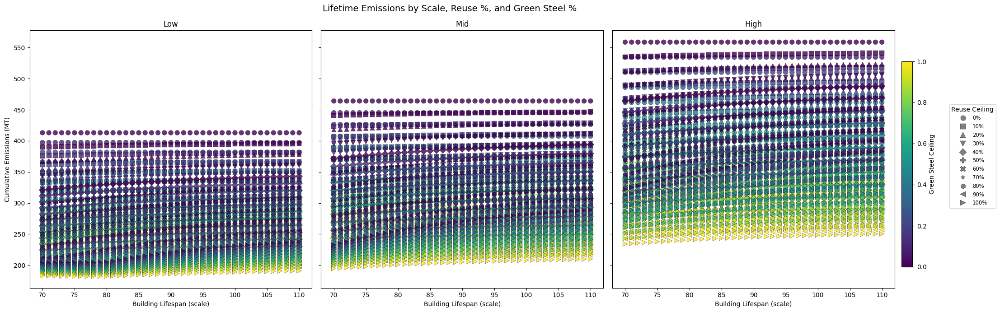

In [301]:
## Senstitivty analysis
def plot_scale_vs_emissions_grid(df_lifetime, title=None,
                                   x_col='scale', y_col='cumulative_emissions',
                                   shape_col='B_reuse', color_col='B_green',
                                   cmap='viridis', figsize=(20, 7)):
    """
    1x3 grid: one panel per scenario (Low, Mid, High).
    x = scale, y = lifetime emissions (MT), marker shape = reuse %, color = green steel %.
    """
    scenarios = ['Low', 'Mid', 'High']
    df_lifetime = df_lifetime.copy()
    df_lifetime['y_MT'] = df_lifetime[y_col] / 1e6

    reuse_levels = sorted(df_lifetime[shape_col].unique())
    green_levels = sorted(df_lifetime[color_col].unique())

    marker_cycle = ['o', 's', '^', 'v', 'D', 'P', 'X', '*', 'h', '<', '>', 'p', '8', 'd']
    marker_map = {level: marker_cycle[i % len(marker_cycle)] for i, level in enumerate(reuse_levels)}

    norm = plt.Normalize(vmin=min(green_levels), vmax=max(green_levels))
    colormap = cm.get_cmap(cmap)

    # shared y-axis range across all three panels for fair comparison
    y_min, y_max = df_lifetime['y_MT'].min(), df_lifetime['y_MT'].max()
    y_pad = (y_max - y_min) * 0.05

    fig, axes = plt.subplots(1, 3, figsize=figsize, sharey=True)

    for ax, scenario_label in zip(axes, scenarios):
        subset = df_lifetime[df_lifetime['scenario'] == scenario_label]

        for reuse_val in reuse_levels:
            reuse_data = subset[subset[shape_col] == reuse_val]
            ax.scatter(
                reuse_data[x_col],
                reuse_data['y_MT'],
                c=reuse_data[color_col],
                cmap=cmap,
                norm=norm,
                marker=marker_map[reuse_val],
                s=60,
                alpha=0.8,
                edgecolors='black',
                linewidths=0.3,
            )

        ax.set_xlabel('Building Lifespan (scale)')
        ax.set_title(scenario_label)
        ax.set_ylim(y_min - y_pad, y_max + y_pad)

    axes[0].set_ylabel('Cumulative Emissions (MT)')

    fig.suptitle(title or 'Lifetime Emissions by Scale, Reuse %, and Green Steel %', fontsize=14)

    # reserve space on the right for shared legends
    fig.subplots_adjust(right=0.85, top=0.85, wspace=0.1)

    # shared colorbar for green steel %
    cbar_ax = fig.add_axes([1, 0.15, 0.012, 0.65])
    sm = cm.ScalarMappable(cmap=colormap, norm=norm)
    sm.set_array([])
    cbar = fig.colorbar(sm, cax=cbar_ax,)
    cbar.set_label('Green Steel Ceiling')

    # shared shape legend for reuse %
    shape_handles = [
        plt.Line2D([0], [0], marker=marker_map[level], color='gray', linestyle='',
                   markersize=8, markeredgecolor='black', markeredgewidth=0.3)
        for level in reuse_levels
    ]
    shape_labels = [f'{level*100:.0f}%' for level in reuse_levels]
    fig.legend(shape_handles, shape_labels, title='Reuse Ceiling',
               loc='center left', bbox_to_anchor=(1.05, 0.5), fontsize='small')

    plt.show()
    return fig, axes


fig, axes = plot_scale_vs_emissions_grid(df_lifetime_emissions)

C:\Users\aorga\AppData\Local\Temp\ipykernel_38548\2923682736.py:26: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  colormap = cm.get_cmap(cmap)
c:\Users\aorga\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.canvas.print_figure(bytes_io, **kw)


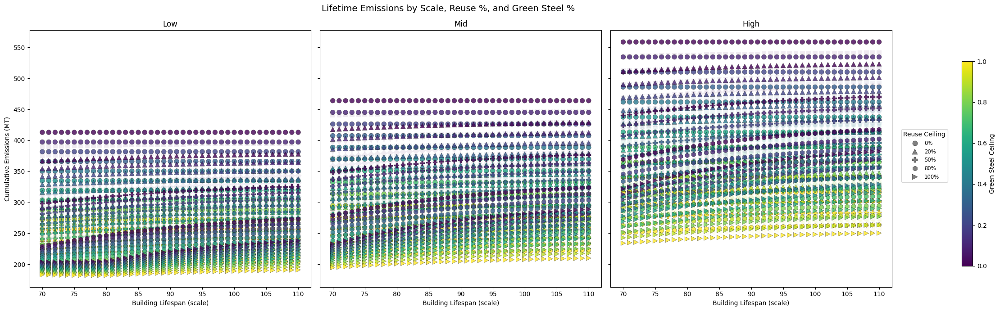

In [302]:
def plot_scale_vs_emissions_grid(df_lifetime, title=None,
                                   x_col='scale', y_col='cumulative_emissions',
                                   shape_col='B_reuse', color_col='B_green',
                                   cmap='viridis', figsize=(20, 7),
                                   highlight_reuse=(0.0, 0.2, 0.5, 0.8, 1.0),
                                   highlight_alpha=0.8, dim_alpha=0.08):
    """
    1x3 grid: one panel per scenario (Low, Mid, High).
    x = scale, y = lifetime emissions (MT), marker shape = reuse %, color = green steel %.
    Only reuse levels in `highlight_reuse` are shown fully opaque; all others are faded.
    """
    scenarios = ['Low', 'Mid', 'High']
    df_lifetime = df_lifetime.copy()
    df_lifetime['y_MT'] = df_lifetime[y_col] / 1e6

    reuse_levels = sorted(df_lifetime[shape_col].unique())
    green_levels = sorted(df_lifetime[color_col].unique())

    marker_cycle = ['o', 's', '^', 'v', 'D', 'P', 'X', '*', 'h', '<', '>', 'p', '8', 'd']
    marker_map = {level: marker_cycle[i % len(marker_cycle)] for i, level in enumerate(reuse_levels)}

    # tolerance-based match against highlight_reuse, to avoid float equality issues
    highlight_set = set(np.round(highlight_reuse, 6))

    norm = plt.Normalize(vmin=min(green_levels), vmax=max(green_levels))
    colormap = cm.get_cmap(cmap)

    y_min, y_max = df_lifetime['y_MT'].min(), df_lifetime['y_MT'].max()
    y_pad = (y_max - y_min) * 0.05

    fig, axes = plt.subplots(1, 3, figsize=figsize, sharey=True)

    for ax, scenario_label in zip(axes, scenarios):
        subset = df_lifetime[df_lifetime['scenario'] == scenario_label]

        # plot dim (non-highlighted) points first, so highlighted ones draw on top
        for reuse_val in reuse_levels:
            is_highlighted = round(reuse_val, 6) in highlight_set
            reuse_data = subset[subset[shape_col] == reuse_val]
            ax.scatter(
                reuse_data[x_col],
                reuse_data['y_MT'],
                c=reuse_data[color_col],
                cmap=cmap,
                norm=norm,
                marker=marker_map[reuse_val],
                s=60,
                alpha=highlight_alpha if is_highlighted else dim_alpha,
                edgecolors='black',
                linewidths=0.3 if is_highlighted else 0,
                zorder=5 if is_highlighted else 1,
            )

        ax.set_xlabel('Building Lifespan (scale)')
        ax.set_title(scenario_label)
        ax.set_ylim(y_min - y_pad, y_max + y_pad)

    axes[0].set_ylabel('Cumulative Emissions (MT)')

    fig.suptitle(title or 'Lifetime Emissions by Scale, Reuse %, and Green Steel %', fontsize=14)

    fig.subplots_adjust(right=0.85, top=0.85, wspace=0.1)

    cbar_ax = fig.add_axes([1.07, 0.15, 0.012, 0.65])
    sm = cm.ScalarMappable(cmap=colormap, norm=norm)
    sm.set_array([])
    cbar = fig.colorbar(sm, cax=cbar_ax)
    cbar.set_label('Green Steel Ceiling')

    # shape legend only for highlighted reuse levels (the ones actually visible)
    highlighted_levels = [lvl for lvl in reuse_levels if round(lvl, 6) in highlight_set]
    shape_handles = [
        plt.Line2D([0], [0], marker=marker_map[level], color='gray', linestyle='',
                   markersize=8, markeredgecolor='black', markeredgewidth=0.3)
        for level in highlighted_levels
    ]
    shape_labels = [f'{level*100:.0f}%' for level in highlighted_levels]
    fig.legend(shape_handles, shape_labels, title='Reuse Ceiling',
               loc='center left', bbox_to_anchor=(1, 0.5), fontsize='small')

    plt.show()
    return fig, axes


fig, axes = plot_scale_vs_emissions_grid(df_lifetime_emissions)

C:\Users\aorga\AppData\Local\Temp\ipykernel_38548\703197904.py:22: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  colormap = cm.get_cmap(cmap)
c:\Users\aorga\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.canvas.print_figure(bytes_io, **kw)


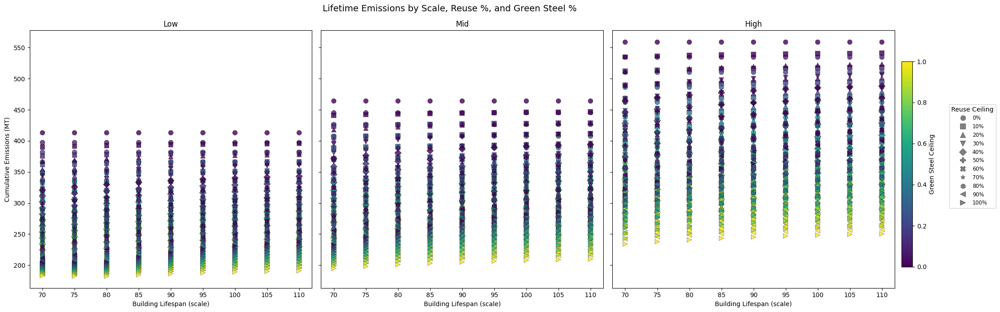

In [303]:
def plot_scale_vs_emissions_grid(df_lifetime, title=None,
                                   x_col='scale', y_col='cumulative_emissions',
                                   shape_col='B_reuse', color_col='B_green',
                                   cmap='viridis', figsize=(20, 7),
                                   scales_to_plot=(70, 75, 80, 85, 90, 95, 100, 105, 110)):
    """
    1x3 grid: one panel per scenario (Low, Mid, High).
    x = scale, y = lifetime emissions (MT), marker shape = reuse %, color = green steel %.
    Only rows whose scale is in scales_to_plot are included.
    """
    scenarios = ['Low', 'Mid', 'High']
    df_lifetime = df_lifetime[df_lifetime[x_col].isin(scales_to_plot)].copy()
    df_lifetime['y_MT'] = df_lifetime[y_col] / 1e6

    reuse_levels = sorted(df_lifetime[shape_col].unique())
    green_levels = sorted(df_lifetime[color_col].unique())

    marker_cycle = ['o', 's', '^', 'v', 'D', 'P', 'X', '*', 'h', '<', '>', 'p', '8', 'd']
    marker_map = {level: marker_cycle[i % len(marker_cycle)] for i, level in enumerate(reuse_levels)}

    norm = plt.Normalize(vmin=min(green_levels), vmax=max(green_levels))
    colormap = cm.get_cmap(cmap)

    # shared y-axis range across all three panels for fair comparison
    y_min, y_max = df_lifetime['y_MT'].min(), df_lifetime['y_MT'].max()
    y_pad = (y_max - y_min) * 0.05

    fig, axes = plt.subplots(1, 3, figsize=figsize, sharey=True)

    for ax, scenario_label in zip(axes, scenarios):
        subset = df_lifetime[df_lifetime['scenario'] == scenario_label]

        for reuse_val in reuse_levels:
            reuse_data = subset[subset[shape_col] == reuse_val]
            ax.scatter(
                reuse_data[x_col],
                reuse_data['y_MT'],
                c=reuse_data[color_col],
                cmap=cmap,
                norm=norm,
                marker=marker_map[reuse_val],
                s=60,
                alpha=0.8,
                edgecolors='black',
                linewidths=0.3,
            )

        ax.set_xlabel('Building Lifespan (scale)')
        ax.set_title(scenario_label)
        ax.set_ylim(y_min - y_pad, y_max + y_pad)
        ax.set_xticks(list(scales_to_plot))

    axes[0].set_ylabel('Cumulative Emissions (MT)')

    fig.suptitle(title or 'Lifetime Emissions by Scale, Reuse %, and Green Steel %', fontsize=14)

    # reserve space on the right for shared legends
    fig.subplots_adjust(right=0.85, top=0.85, wspace=0.1)

    # shared colorbar for green steel %
    cbar_ax = fig.add_axes([1, 0.15, 0.012, 0.65])
    sm = cm.ScalarMappable(cmap=colormap, norm=norm)
    sm.set_array([])
    cbar = fig.colorbar(sm, cax=cbar_ax,)
    cbar.set_label('Green Steel Ceiling')

    # shared shape legend for reuse %
    shape_handles = [
        plt.Line2D([0], [0], marker=marker_map[level], color='gray', linestyle='',
                   markersize=8, markeredgecolor='black', markeredgewidth=0.3)
        for level in reuse_levels
    ]
    shape_labels = [f'{level*100:.0f}%' for level in reuse_levels]
    fig.legend(shape_handles, shape_labels, title='Reuse Ceiling',
               loc='center left', bbox_to_anchor=(1.05, 0.5), fontsize='small')

    plt.show()
    return fig, axes


fig, axes = plot_scale_vs_emissions_grid(df_lifetime_emissions)

C:\Users\aorga\AppData\Local\Temp\ipykernel_38548\3871569467.py:27: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  colormap = cm.get_cmap(cmap)
c:\Users\aorga\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.canvas.print_figure(bytes_io, **kw)


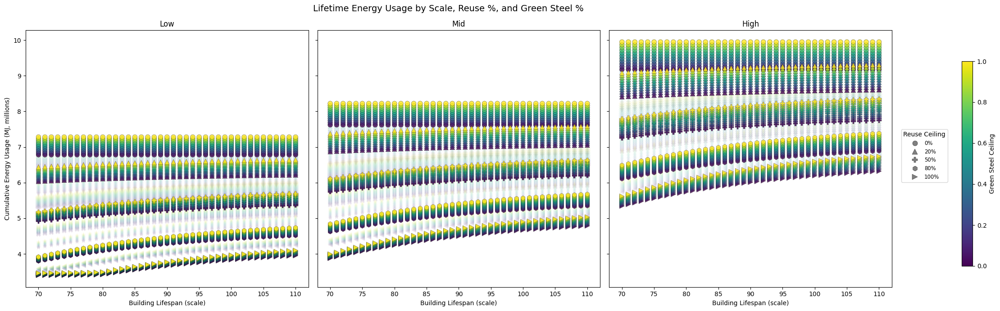

In [319]:
def plot_scale_vs_energy_grid(df_lifetime, title=None,
                                x_col='scale', y_col='cumulative_energy',
                                shape_col='B_reuse', color_col='B_green',
                                cmap='viridis', figsize=(20, 7),
                                highlight_reuse=(0.0, 0.2, 0.5, 0.8, 1.0),
                                highlight_alpha=0.8, dim_alpha=0.08):
    """
    1x3 grid: one panel per scenario (Low, Mid, High).
    x = scale, y = lifetime energy usage (millions of MJ), marker shape = reuse %,
    color = green steel %. Only reuse levels in `highlight_reuse` are shown fully opaque;
    all others are faded.
    """
    scenarios = ['Low', 'Mid', 'High']
    df_lifetime = df_lifetime.copy()
    df_lifetime['y_MJ'] = df_lifetime[y_col] / 1e6

    reuse_levels = sorted(df_lifetime[shape_col].unique())
    green_levels = sorted(df_lifetime[color_col].unique())

    marker_cycle = ['o', 's', '^', 'v', 'D', 'P', 'X', '*', 'h', '<', '>', 'p', '8', 'd']
    marker_map = {level: marker_cycle[i % len(marker_cycle)] for i, level in enumerate(reuse_levels)}

    # tolerance-based match against highlight_reuse, to avoid float equality issues
    highlight_set = set(np.round(highlight_reuse, 6))

    norm = plt.Normalize(vmin=min(green_levels), vmax=max(green_levels))
    colormap = cm.get_cmap(cmap)

    y_min, y_max = df_lifetime['y_MJ'].min(), df_lifetime['y_MJ'].max()
    y_pad = (y_max - y_min) * 0.05

    fig, axes = plt.subplots(1, 3, figsize=figsize, sharey=True)

    for ax, scenario_label in zip(axes, scenarios):
        subset = df_lifetime[df_lifetime['scenario'] == scenario_label]

        # plot dim (non-highlighted) points first, so highlighted ones draw on top
        for reuse_val in reuse_levels:
            is_highlighted = round(reuse_val, 6) in highlight_set
            reuse_data = subset[subset[shape_col] == reuse_val]
            ax.scatter(
                reuse_data[x_col],
                reuse_data['y_MJ'],
                c=reuse_data[color_col],
                cmap=cmap,
                norm=norm,
                marker=marker_map[reuse_val],
                s=60,
                alpha=highlight_alpha if is_highlighted else dim_alpha,
                edgecolors='black',
                linewidths=0.3 if is_highlighted else 0,
                zorder=5 if is_highlighted else 1,
            )

        ax.set_xlabel('Building Lifespan (scale)')
        ax.set_title(scenario_label)
        ax.set_ylim(y_min - y_pad, y_max + y_pad)

    axes[0].set_ylabel('Cumulative Energy Usage (MJ, millions)')

    fig.suptitle(title or 'Lifetime Energy Usage by Scale, Reuse %, and Green Steel %', fontsize=14)

    fig.subplots_adjust(right=0.85, top=0.85, wspace=0.1)

    cbar_ax = fig.add_axes([1.07, 0.15, 0.012, 0.65])
    sm = cm.ScalarMappable(cmap=colormap, norm=norm)
    sm.set_array([])
    cbar = fig.colorbar(sm, cax=cbar_ax)
    cbar.set_label('Green Steel Ceiling')

    # shape legend only for highlighted reuse levels (the ones actually visible)
    highlighted_levels = [lvl for lvl in reuse_levels if round(lvl, 6) in highlight_set]
    shape_handles = [
        plt.Line2D([0], [0], marker=marker_map[level], color='gray', linestyle='',
                   markersize=8, markeredgecolor='black', markeredgewidth=0.3)
        for level in highlighted_levels
    ]
    shape_labels = [f'{level*100:.0f}%' for level in highlighted_levels]
    fig.legend(shape_handles, shape_labels, title='Reuse Ceiling',
               loc='center left', bbox_to_anchor=(1, 0.5), fontsize='small')

    plt.show()
    return fig, axes


fig, axes = plot_scale_vs_energy_grid(df_lifetime_energy)

In [ ]:
df_lifetime_emissions

,scale,draw_id,cumulative_emissions,B_reuse,B_green,scenario
0,70,0,4.129988e+08,0.0,0.0,Low
1,70,1,3.973725e+08,0.0,0.1,Low
2,70,2,3.817461e+08,0.0,0.2,Low
3,70,3,3.661197e+08,0.0,0.3,Low
4,70,4,3.504933e+08,0.0,0.4,Low
...,...,...,...,...,...,...
7618,90,116,2.924763e+08,1.0,0.6,High
7619,90,117,2.806950e+08,1.0,0.7,High
7620,90,118,2.689138e+08,1.0,0.8,High
7621,90,119,2.571325e+08,1.0,0.9,High


In [304]:
df_lifetime_emissions[df_lifetime_emissions['scenario'] == 'Mid'].sort_values(
    'cumulative_emissions', ascending=False
).head(1)

,scale,draw_id,cumulative_emissions,B_reuse,B_green,scenario
9317,106,0,4.640427e+08,0.0,0.0,Mid


In [308]:
df_lifetime_emissions[
    (df_lifetime_emissions['scale'] == 110) &
    (df_lifetime_emissions['scenario'] == 'Mid') &
    (df_lifetime_emissions['B_reuse'] == 1.0) &
    (df_lifetime_emissions['B_green'] == 1.0)
]

,scale,draw_id,cumulative_emissions,B_reuse,B_green,scenario
9921,110,120,2.099423e+08,1.0,1.0,Mid


In [309]:
df_lifetime_emissions

,scale,draw_id,cumulative_emissions,B_reuse,B_green,scenario
0,70,0,4.129988e+08,0.0,0.0,Low
1,70,1,3.973725e+08,0.0,0.1,Low
2,70,2,3.817461e+08,0.0,0.2,Low
3,70,3,3.661197e+08,0.0,0.3,Low
4,70,4,3.504933e+08,0.0,0.4,Low
...,...,...,...,...,...,...
14878,110,116,3.031915e+08,1.0,0.6,High
14879,110,117,2.900067e+08,1.0,0.7,High
14880,110,118,2.768219e+08,1.0,0.8,High
14881,110,119,2.636371e+08,1.0,0.9,High


### Old LCA

In [ ]:
# flows = all_flows.loc[2024:2100]

# # Find all ssp suffixes present (ssp1, ssp2, ...) based on inflow_ column names
# ssp_names = sorted({col.replace('inflow_', '') for col in flows.columns if col.startswith('inflow_')})

# emissions = pd.DataFrame(index=flows.index)

# for ssp in ssp_names:
#     inflow = flows[f'inflow_{ssp}']
#     outflow = flows[f'outflow_{ssp}']
    
#     # Typical (virgin) steel production emissions
#     emissions[f'typical_co2_{ssp}'] = inflow * production_co2
    
#     # Reused steel emissions: outflow fabricated + remainder produced new
#     emissions[f'reused_co2_{ssp}'] = (outflow * fabrication_co2) + ((inflow - outflow) * production_co2)


# emissions = emissions/1e3

# emissions

In [ ]:
# fig, axes = plt.subplots(2, 3, figsize=(10, 5), sharex=True)
# axes = axes.flatten()

# for ax, ssp in zip(axes, ssp_names):
#     ax.plot(emissions.index, emissions[f'typical_co2_{ssp}'], label='Virgin production', color='#d62728')
#     ax.plot(emissions.index, emissions[f'reused_co2_{ssp}'], label='Reuse', color='#2ca02c')
#     ax.set_title(ssp.upper())
#     ax.set_ylabel('CO2 emissions (MT)')
#     ax.grid(alpha=0.3)

# # Hide any unused subplot(s) — e.g. if you have 5 SSPs in a 6-slot grid
# for ax in axes[len(ssp_names):]:
#     ax.axis('off')

# # Shared legend, built from the first panel's lines
# handles, labels = axes[0].get_legend_handles_labels()
# fig.legend(handles, labels, loc='lower center', ncol=2, bbox_to_anchor=(0.5, -0.02), fontsize=10)
# fig.suptitle('Annual Emissions by SSP and Steel Source')

# for ax in axes[-2:]:
#     if ax.get_visible():
#         ax.set_xlabel('Year')

# plt.tight_layout(rect=[0, 0.03, 1, 1])  # leave room at bottom for legend
# plt.savefig('emissions_by_ssp.png', dpi=150, bbox_inches='tight')
# plt.show()